# Tarefa investigativa: erros em métodos de interpolação

### Aplicação: reconstrução da temperatura em uma barra aquecida

Uma barra homogênea de comprimento $L=6$ m está sujeita a temperaturas prescritas nas extremidades e recebe calor de uma fonte distribuída em seu interior. Sensores medem a temperatura em posições discretas. A equipe precisa estimar a temperatura em posições onde não há sensor e avaliar a incerteza dessas estimativas.

Esta atividade combina um modelo simplificado de transferência de calor com interpolação numérica. O objetivo não é resolver a equação diferencial de calor por diferenças finitas. O perfil analítico será usado como referência, para que os erros de diferentes métodos de interpolação possam ser medidos e comparados.

Você vai comparar **polinômio global de Lagrange** e uma **spline cúbica**, primeiro com dados exatos e depois com medições perturbadas por ruído.


## 1. Problema físico e equação de transferência de calor

### 1.1 Modelo físico

Considere uma barra sólida homogênea, com comprimento $L=6$ m e seção transversal constante. A temperatura varia principalmente ao longo do eixo $x$. As extremidades são mantidas a temperaturas conhecidas. No interior, uma fonte térmica volumétrica distribui energia ao longo da barra.

A equação geral de energia térmica, para propriedades constantes e sem mudança de fase, pode ser escrita como

$$\rho c_p\frac{\partial T}{\partial t}=k\nabla^2T+\dot q^{\prime\prime\prime}-\rho c_p\,\mathbf{u}\cdot\nabla T,$$

em que $T$ é a temperatura (K ou °C para diferenças), $t$ é o tempo (s), $\rho$ é a massa específica (kg m$^{-3}$), $c_p$ é o calor específico (J kg$^{-1}$ K$^{-1}$), $k$ é a condutividade térmica (W m$^{-1}$ K$^{-1}$), $\dot q^{\prime\prime\prime}$ é a geração volumétrica de calor (W m$^{-3}$) e $\mathbf{u}$ representa o movimento de um fluido, quando há advecção.

Para esta atividade, adotamos uma **barra sólida em regime estacionário**, sem escoamento interno, com condução unidimensional e geração de calor. Assim, $\partial T/\partial t=0$, $\mathbf{u}=0$ e $\nabla^2T=d^2T/dx^2$. A equação fica

$$k\frac{d^2T}{dx^2}+\dot q^{\prime\prime\prime}(x)=0,\qquad 0<x<L,$$

com condições de contorno de Dirichlet

$$T(0)=18\ ^\circ\mathrm C,\qquad T(L)=20.4\ ^\circ\mathrm C.$$

O primeiro termo representa a condução: diferenças espaciais de temperatura geram fluxo de calor. O termo $\dot q^{\prime\prime\prime}(x)$ representa energia adicionada por unidade de volume e de tempo. O sinal positivo de $\dot q^{\prime\prime\prime}$ indica geração interna de calor.

### 1.2 Perfil de referência usado no experimento

Para criar um caso com solução conhecida, definimos $\xi=x/L$ e adotamos

$$T(x)=18+2.4\,\xi+2.5\sin(\pi\xi),\qquad \xi=\frac{x}{L},\quad 0\le x\le L.$$

A parcela linear garante as temperaturas prescritas nas extremidades. A parcela senoidal representa um aquecimento distribuído mais intenso no interior e nulo nas bordas. Derivando duas vezes em relação à coordenada física $x$,

$$\frac{d^2T}{dx^2}=-\frac{2.5\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Portanto, esse perfil satisfaz a equação estacionária se a geração volumétrica for

$$\dot q^{\prime\prime\prime}(x)=\frac{2.5\,k\pi^2}{L^2}\sin\left(\frac{\pi x}{L}\right).$$

Como $\sin(\pi x/L)\ge0$ dentro da barra, a fonte é não negativa. Não precisamos escolher um valor numérico para $k$: o objetivo é verificar a coerência do perfil e estudar a interpolação. A função analítica é uma referência idealizada; em uma aplicação experimental, seria preciso estimar propriedades, fontes, perdas e condições de contorno.

### 1.3 Questão investigativa

**Como a resposta depende da quantidade e posição dos sensores e do ruído de medição?**



### O que significa erro de interpolação?

Em um ponto de avaliação $x$, o erro assinado é $e(x)=p(x)-T(x)$. O erro absoluto é $|e(x)|$. Como a interpolação reproduz os nós, o erro nesses pontos pode ser praticamente zero; por isso, avaliaremos também muitos pontos **entre** os nós.

Usaremos: erro máximo absoluto $E_{max}=\max_j|e_j|$; erro médio absoluto (MAE) $=\frac{1}{m}\sum_j|e_j|$; raiz do erro quadrático médio (RMSE) $=\sqrt{\frac{1}{m}\sum_j e_j^2}$. O RMSE penaliza mais erros grandes.

## 2. Figura do problema e preparação do ambiente

A figura esquematiza a barra, os sensores, as temperaturas nas extremidades e a fonte térmica interna. A curva corresponde ao perfil de referência usado no experimento. Os pontos são as posições onde os sensores amostram a temperatura.

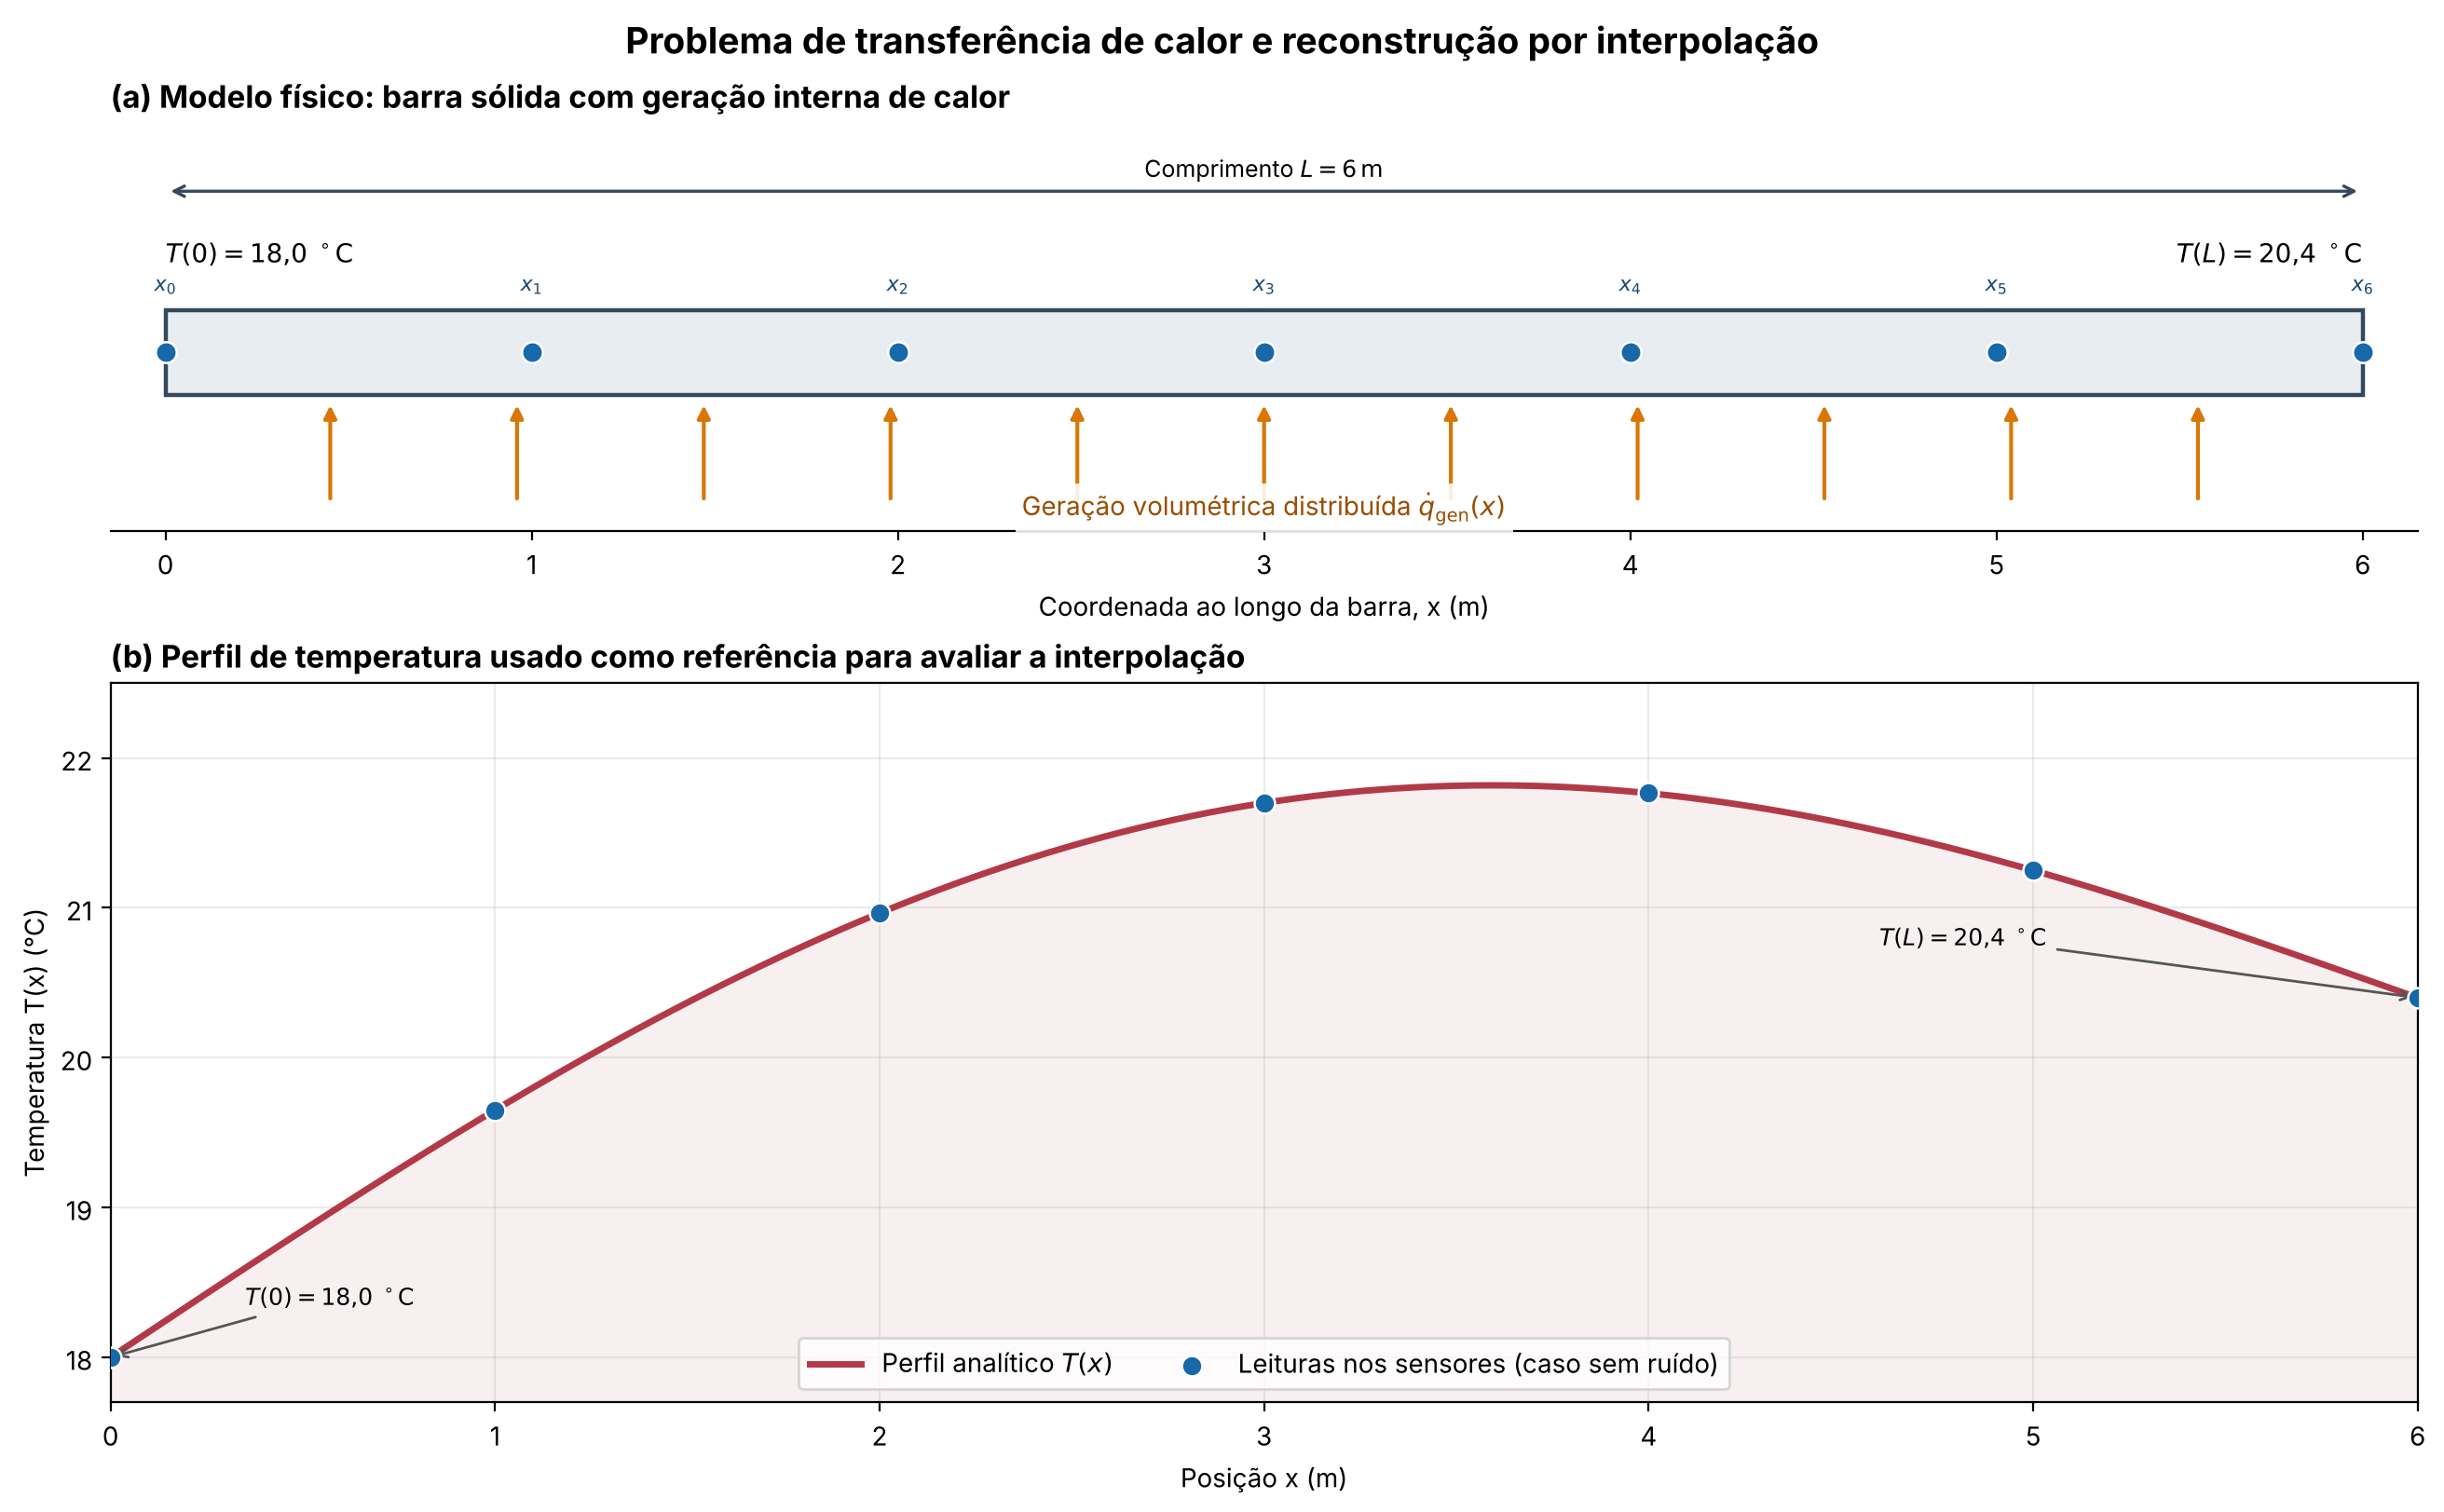

Temperaturas nas extremidades: T(0)=18.0 °C e T(L)=20.4 °C


In [1]:
# Preparação do modelo e bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import BarycentricInterpolator, interp1d, CubicSpline
from matplotlib.patches import Rectangle

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.figsize"] = (9, 5)
L = 6.0  # comprimento da barra, m

def temperatura_real(x):
    """Perfil analítico de referência em °C; x é dado em metros."""
    x = np.asarray(x, dtype=float)
    xi = x/L
    return 18 + 2.4*xi + 2.5*np.sin(np.pi*xi)

x_min, x_max = 0.0, L
x_fino = np.linspace(x_min, x_max, 2001)
T_fino = temperatura_real(x_fino)

# Figura do problema: esquema físico e perfil analítico em painéis separados

x_sensores_fig = np.linspace(0, L, 7)
T_sensores_fig = temperatura_real(x_sensores_fig)

fig = plt.figure(figsize=(13, 8), constrained_layout=True)
gs = fig.add_gridspec(2, 1, height_ratios=[0.85, 1.5])
ax_esq = fig.add_subplot(gs[0])
ax_perfil = fig.add_subplot(gs[1])

# Painel (a): barra física, sensores e fonte interna distribuída
ax_esq.set_title("(a) Modelo físico: barra sólida com geração interna de calor", loc="left", fontsize=12, weight="bold")
barra_y, barra_h = 0.40, 0.25
ax_esq.add_patch(Rectangle((0, barra_y), L, barra_h, facecolor="#e8edf2",
                           edgecolor="#34495e", linewidth=1.6, zorder=1))
# Sensores ao longo do eixo da barra
ax_esq.scatter(x_sensores_fig, np.full_like(x_sensores_fig, barra_y+barra_h/2),
               s=65, marker="o", facecolor="#1769aa", edgecolor="white", linewidth=0.9,
               zorder=4, label="Sensores")
# Aquecimento interno: setas iguais identificam geração distribuída, sem sugerir fluxo de calor externo
for xpos in np.linspace(0.45, 5.55, 11):
    ax_esq.annotate("", xy=(xpos, barra_y-0.015), xytext=(xpos, 0.08),
                    arrowprops={"arrowstyle":"-|>", "color":"#d97706", "lw":1.5}, zorder=3)
ax_esq.text(L/2, 0.015, r"Geração volumétrica distribuída $\dot{q}_{\mathrm{gen}}(x)$",
            ha="center", va="bottom", color="#9a4d00", fontsize=10,
            bbox={"facecolor":"white", "edgecolor":"none", "alpha":0.88, "pad":2.5})
ax_esq.text(0, 0.77, r"$T(0)=18{,}0\ ^\circ\mathrm{C}$", ha="left", va="bottom", fontsize=10)
ax_esq.text(L, 0.77, r"$T(L)=20{,}4\ ^\circ\mathrm{C}$", ha="right", va="bottom", fontsize=10)
# Linha de dimensão e eixo longitudinal
ax_esq.annotate("", xy=(L, 1.00), xytext=(0, 1.00),
                arrowprops={"arrowstyle":"<->", "color":"#34495e", "lw":1.2})
ax_esq.text(L/2, 1.025, r"Comprimento $L=6\,\mathrm{m}$", ha="center", va="bottom", fontsize=9)
for i, xpos in enumerate(x_sensores_fig):
    ax_esq.text(xpos, barra_y+barra_h+0.04, rf"$x_{i}$", ha="center", va="bottom", fontsize=8, color="#174a73")
ax_esq.set_xlim(-0.15, L+0.15); ax_esq.set_ylim(0, 1.2)
ax_esq.set_xlabel("Coordenada ao longo da barra, x (m)")
ax_esq.set_yticks([]); ax_esq.grid(False)
for spine in ["left", "right", "top"]: ax_esq.spines[spine].set_visible(False)

# Painel (b): curva de referência e posições amostradas
ax_perfil.set_title("(b) Perfil de temperatura usado como referência para avaliar a interpolação",
                    loc="left", fontsize=12, weight="bold")
ax_perfil.plot(x_fino, T_fino, color="#b23a48", linewidth=2.5,
               label=r"Perfil analítico $T(x)$", zorder=2)
ax_perfil.scatter(x_sensores_fig, T_sensores_fig, s=62, marker="o",
                  facecolor="#1769aa", edgecolor="white", linewidth=0.9,
                  label="Leituras nos sensores (caso sem ruído)", zorder=4)
ax_perfil.fill_between(x_fino, T_fino, np.min(T_fino)-0.3,
                       color="#b23a48", alpha=0.08, zorder=1)
ax_perfil.annotate(r"$T(0)=18{,}0\ ^\circ\mathrm{C}$",
                   xy=(0, temperatura_real(0)), xytext=(0.35, 18.35),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.annotate(r"$T(L)=20{,}4\ ^\circ\mathrm{C}$",
                   xy=(L, temperatura_real(L)), xytext=(4.6, 20.75),
                   arrowprops={"arrowstyle":"->", "color":"#555"}, fontsize=9)
ax_perfil.set_xlim(0, L); ax_perfil.set_ylim(17.7, 22.5)
ax_perfil.set_xlabel("Posição x (m)")
ax_perfil.set_ylabel("Temperatura T(x) (°C)")
ax_perfil.grid(True, alpha=0.25); ax_perfil.legend(loc="lower center", ncol=2, frameon=True)
fig.suptitle("Problema de transferência de calor e reconstrução por interpolação", fontsize=14, weight="bold")
plt.show()

print(f"Temperaturas nas extremidades: T(0)={temperatura_real(0):.1f} °C e T(L)={temperatura_real(L):.1f} °C")

Spline quadrática

In [2]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


## 3. Métodos de interpolação e métricas de erro

O interpolador global de Lagrange passa por todos os sensores usando um único polinômio. Usamos a forma baricêntrica, que evita expandir diretamente os coeficientes e costuma ser numericamente mais estável.

As splines constroem polinômios por intervalos. A spline linear conecta pontos por retas. A quadrática deste notebook impõe continuidade da função e da primeira derivada e usa a condição de contorno $c_0=0$ no primeiro intervalo. A spline cúbica natural impõe continuidade até a segunda derivada e segunda derivada nula nas extremidades.

Para quantificar a diferença, calculamos $e(x)=T_{interp}(x)-T_{ref}(x)$. O erro máximo mostra o pior desvio na malha. O MAE dá o desvio absoluto médio. O RMSE penaliza mais os erros de grande magnitude. Todos têm unidade de graus Celsius.

A malha fina serve como conjunto de pontos de avaliação: os valores nela não são novos sensores. Assim, a comparação mede desempenho entre os nós.

In [3]:
def spline_quadratica_coef(x, y):
    """Spline quadrática C1 com condição c_0=0; retorna a,b,c locais."""
    x = np.asarray(x, float); y = np.asarray(y, float)
    n = len(x)-1
    if n < 1 or len(y) != len(x) or np.any(np.diff(x) <= 0):
        raise ValueError("x deve ser crescente e ter o mesmo tamanho de y.")
    A = np.zeros((3*n, 3*n)); rhs = np.zeros(3*n); row = 0
    # S_i(x_i)=y_i
    for i in range(n):
        A[row, i] = 1; rhs[row] = y[i]; row += 1
    # S_i(x_(i+1))=y_(i+1)
    for i in range(n):
        h = x[i+1]-x[i]
        A[row, i] = 1; A[row, n+i] = h; A[row, 2*n+i] = h*h
        rhs[row] = y[i+1]; row += 1
    # Continuidade da primeira derivada nos nós internos
    for i in range(n-1):
        h = x[i+1]-x[i]
        A[row, n+i] = 1; A[row, 2*n+i] = 2*h; A[row, n+i+1] = -1
        row += 1
    # Condição de contorno: c_0=0
    A[row, 2*n] = 1
    coef = np.linalg.solve(A, rhs)
    return coef[:n], coef[n:2*n], coef[2*n:]

def spline_quadratica_avalia(x, coef, xq):
    a, b, c = coef
    xq = np.asarray(xq, dtype=float)
    idx = np.clip(np.searchsorted(x, xq, side="right")-1, 0, len(a)-1)
    t = xq-x[idx]
    return a[idx] + b[idx]*t + c[idx]*t**2

def criar_metodos(x, y):
    """Retorna dicionário: interpoladores callable para quatro métodos."""
    lagrange = BarycentricInterpolator(x, y)
    linear = interp1d(x, y, kind="linear", bounds_error=True)
    quad_coef = spline_quadratica_coef(x, y)
    quad = lambda z: spline_quadratica_avalia(x, quad_coef, z)
    cubica = CubicSpline(x, y, bc_type="natural")
    return {"Lagrange global": lagrange,
            "Spline linear": linear,
            "Spline quadrática": quad,
            "Spline cúbica natural": cubica}

def calcular_metricas(metodos, x_teste, y_verdadeiro):
    linhas = []
    for nome, metodo in metodos.items():
        erro = np.asarray(metodo(x_teste))-np.asarray(y_verdadeiro)
        linhas.append({"Método": nome,
                       "Erro máximo (°C)": np.max(np.abs(erro)),
                       "MAE (°C)": np.mean(np.abs(erro)),
                       "RMSE (°C)": np.sqrt(np.mean(erro**2))})
    return pd.DataFrame(linhas).sort_values("RMSE (°C)").reset_index(drop=True)

print("Funções de interpolação e métricas definidas.")

Funções de interpolação e métricas definidas.


> **Nota:** esta célula repete, sem nenhuma alteração, as funções definidas na célula "Spline quadrática". Como a segunda definição apenas substitui a primeira pelo mesmo código, a repetição não interfere nos resultados, e por isso foi mantida para respeitar a estrutura original do enunciado.

In [4]:
# Identidade visual fixa por método (cor + traço + marcador), para que os
# gráficos sejam legíveis mesmo impressos em preto e branco.
ESTILO = {
    "Lagrange global":       dict(color="#2a78d6", ls="-",  marker="o"),
    "Spline linear":         dict(color="#eb6834", ls="--", marker="s"),
    "Spline quadrática":     dict(color="#1baf7a", ls="-.", marker="^"),
    "Spline cúbica natural": dict(color="#eda100", ls=":",  marker="D"),
    "Lagrange Chebyshev":    dict(color="#e87ba4", ls="-",  marker="v"),
    "Spline de suavização":  dict(color="#008300", ls="-",  marker="P"),
}
COR_REF = "#3b3b3b"   # curva verdadeira
import time
from IPython.display import display

## Etapa 1 — Interpolação com dados exatos
Suponha primeiro que os sensores sejam perfeitos. Coloque sete sensores em posições igualmente espaçadas, incluindo as duas extremidades. Os valores registrados são então exatamente $T(x_i)$.

### Passo a passo
1. Construa o vetor das posições e avalie o perfil de referência nesses pontos.
2. Crie a interpolação com `criar_metodos`.
3. Avalie cada método em `x_fino`, uma malha densa entre 0 e 6 m.
4. Calcule $E_{max}$, MAE e RMSE comparando cada curva com `T_fino`.
5. Faça um gráfico das temperaturas e outro dos erros assinados.




,Método,Erro máximo (°C),MAE (°C),RMSE (°C)
0,Lagrange global,8.47e-05,1.92e-05,3.27e-05
1,Spline cúbica natural,5.06e-04,1.84e-04,2.39e-04
2,Spline quadrática,2.39e-02,1.50e-02,1.65e-02
3,Spline linear,8.23e-02,3.65e-02,4.40e-02


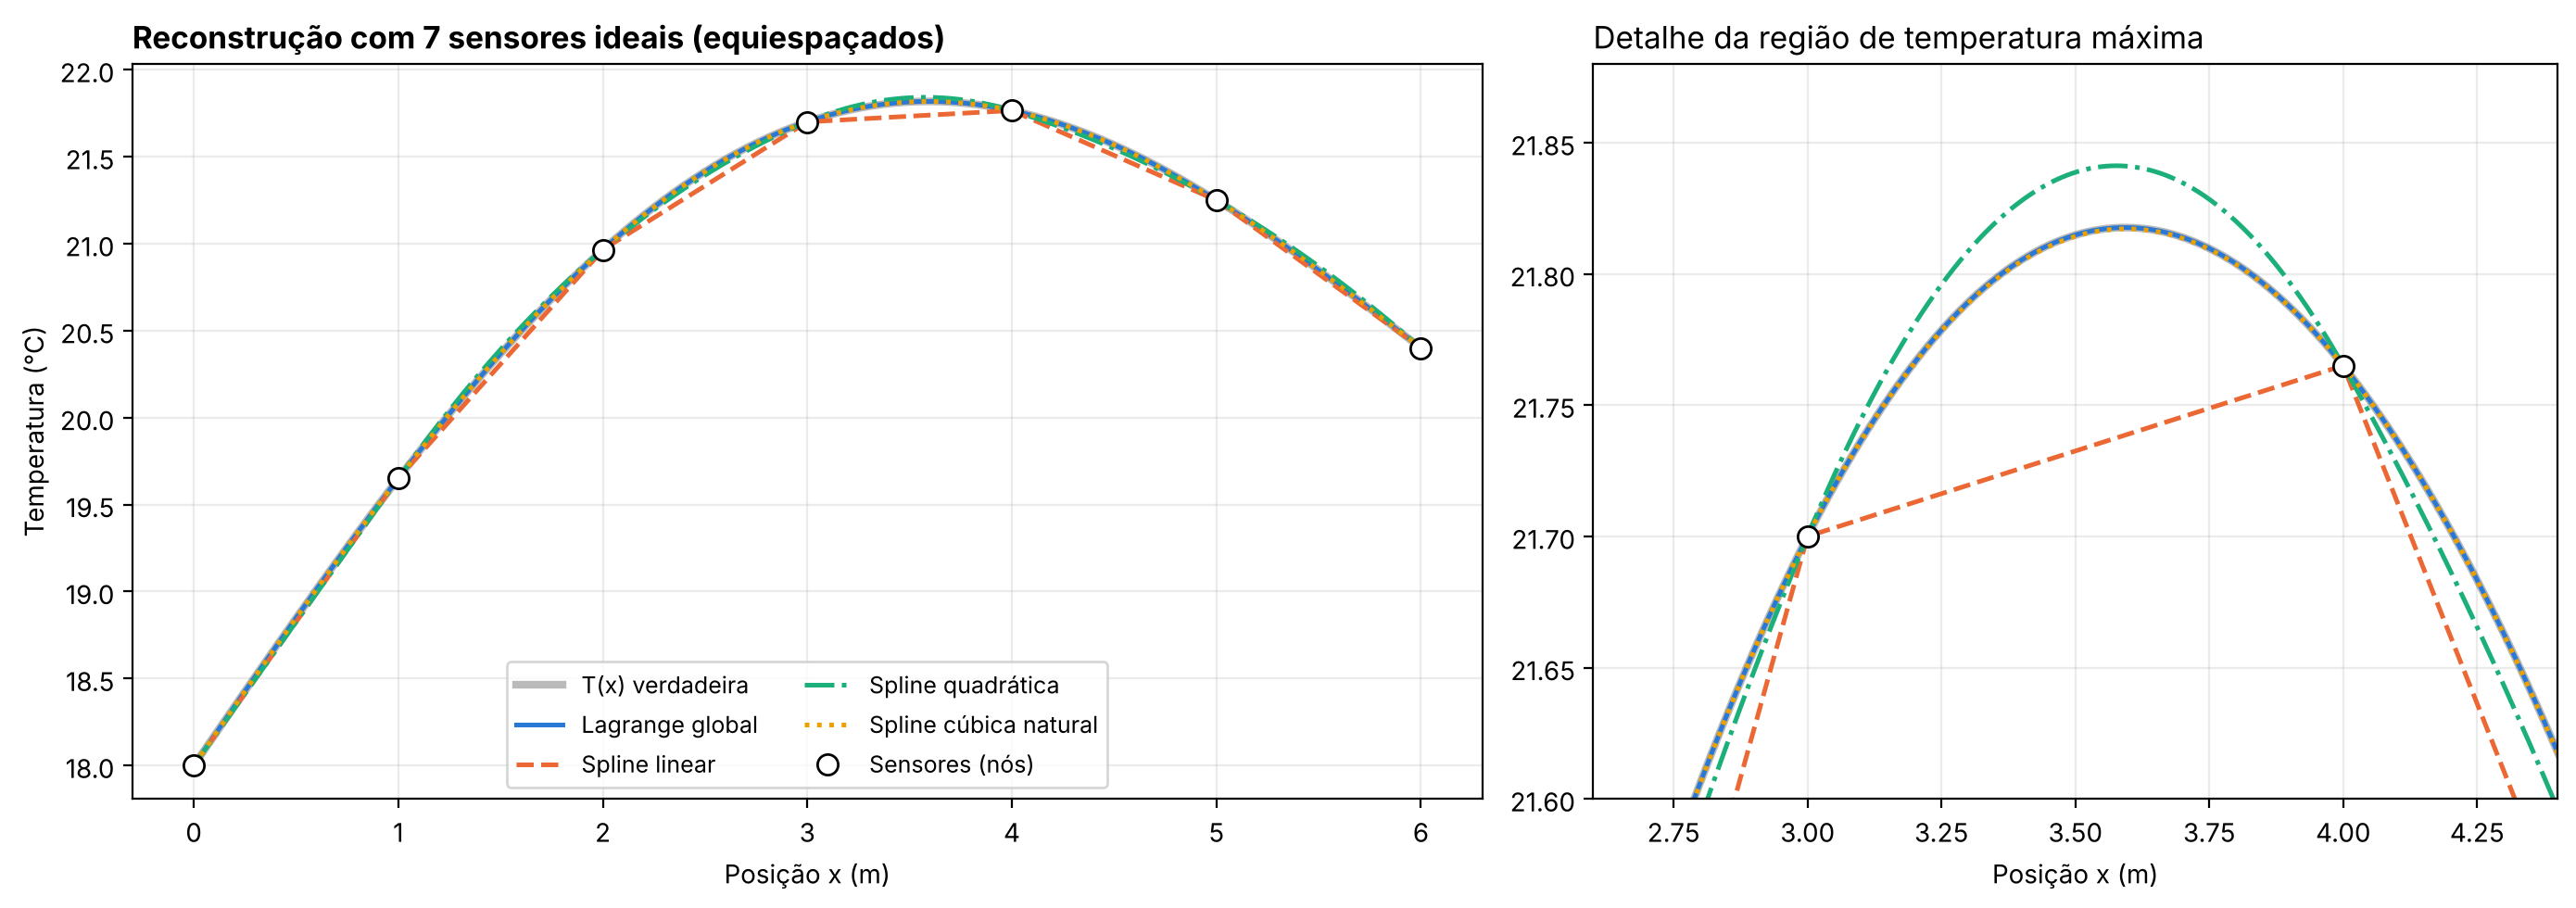

In [5]:

x_nos_7 = np.linspace(x_min, x_max, 7)
y_nos_7 = temperatura_real(x_nos_7)
metodos_7 = criar_metodos(x_nos_7, y_nos_7)

# Comparação contra o perfil analítico nos 2001 pontos de teste
metricas_7 = calcular_metricas(metodos_7, x_fino, T_fino)
display(metricas_7.style.format({c: "{:.2e}" for c in metricas_7.columns[1:]}))

# Curvas reconstruídas sobre o perfil de referência
fig, (ax, axz) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.4, 1]})
for a in (ax, axz):
    a.plot(x_fino, T_fino, color=COR_REF, lw=3, alpha=0.35, label="T(x) verdadeira")
    for nome, f in metodos_7.items():
        s = ESTILO[nome]
        a.plot(x_fino, f(x_fino), color=s["color"], ls=s["ls"], lw=1.8, label=nome)
    a.plot(x_nos_7, y_nos_7, "o", ms=8, mfc="white", mec="black", label="Sensores (nós)")
    a.set_xlabel("Posição x (m)"); a.grid(alpha=0.25)
ax.set_ylabel("Temperatura (°C)")
ax.set_title("Reconstrução com 7 sensores ideais (equiespaçados)", loc="left", weight="bold")
ax.legend(loc="lower center", ncol=2, fontsize=9)
# Ampliação da região mais quente, onde a curvatura é maior
axz.set_xlim(2.6, 4.4); axz.set_ylim(21.6, 21.88)
axz.set_title("Detalhe da região de temperatura máxima", loc="left")
plt.tight_layout(); plt.show()


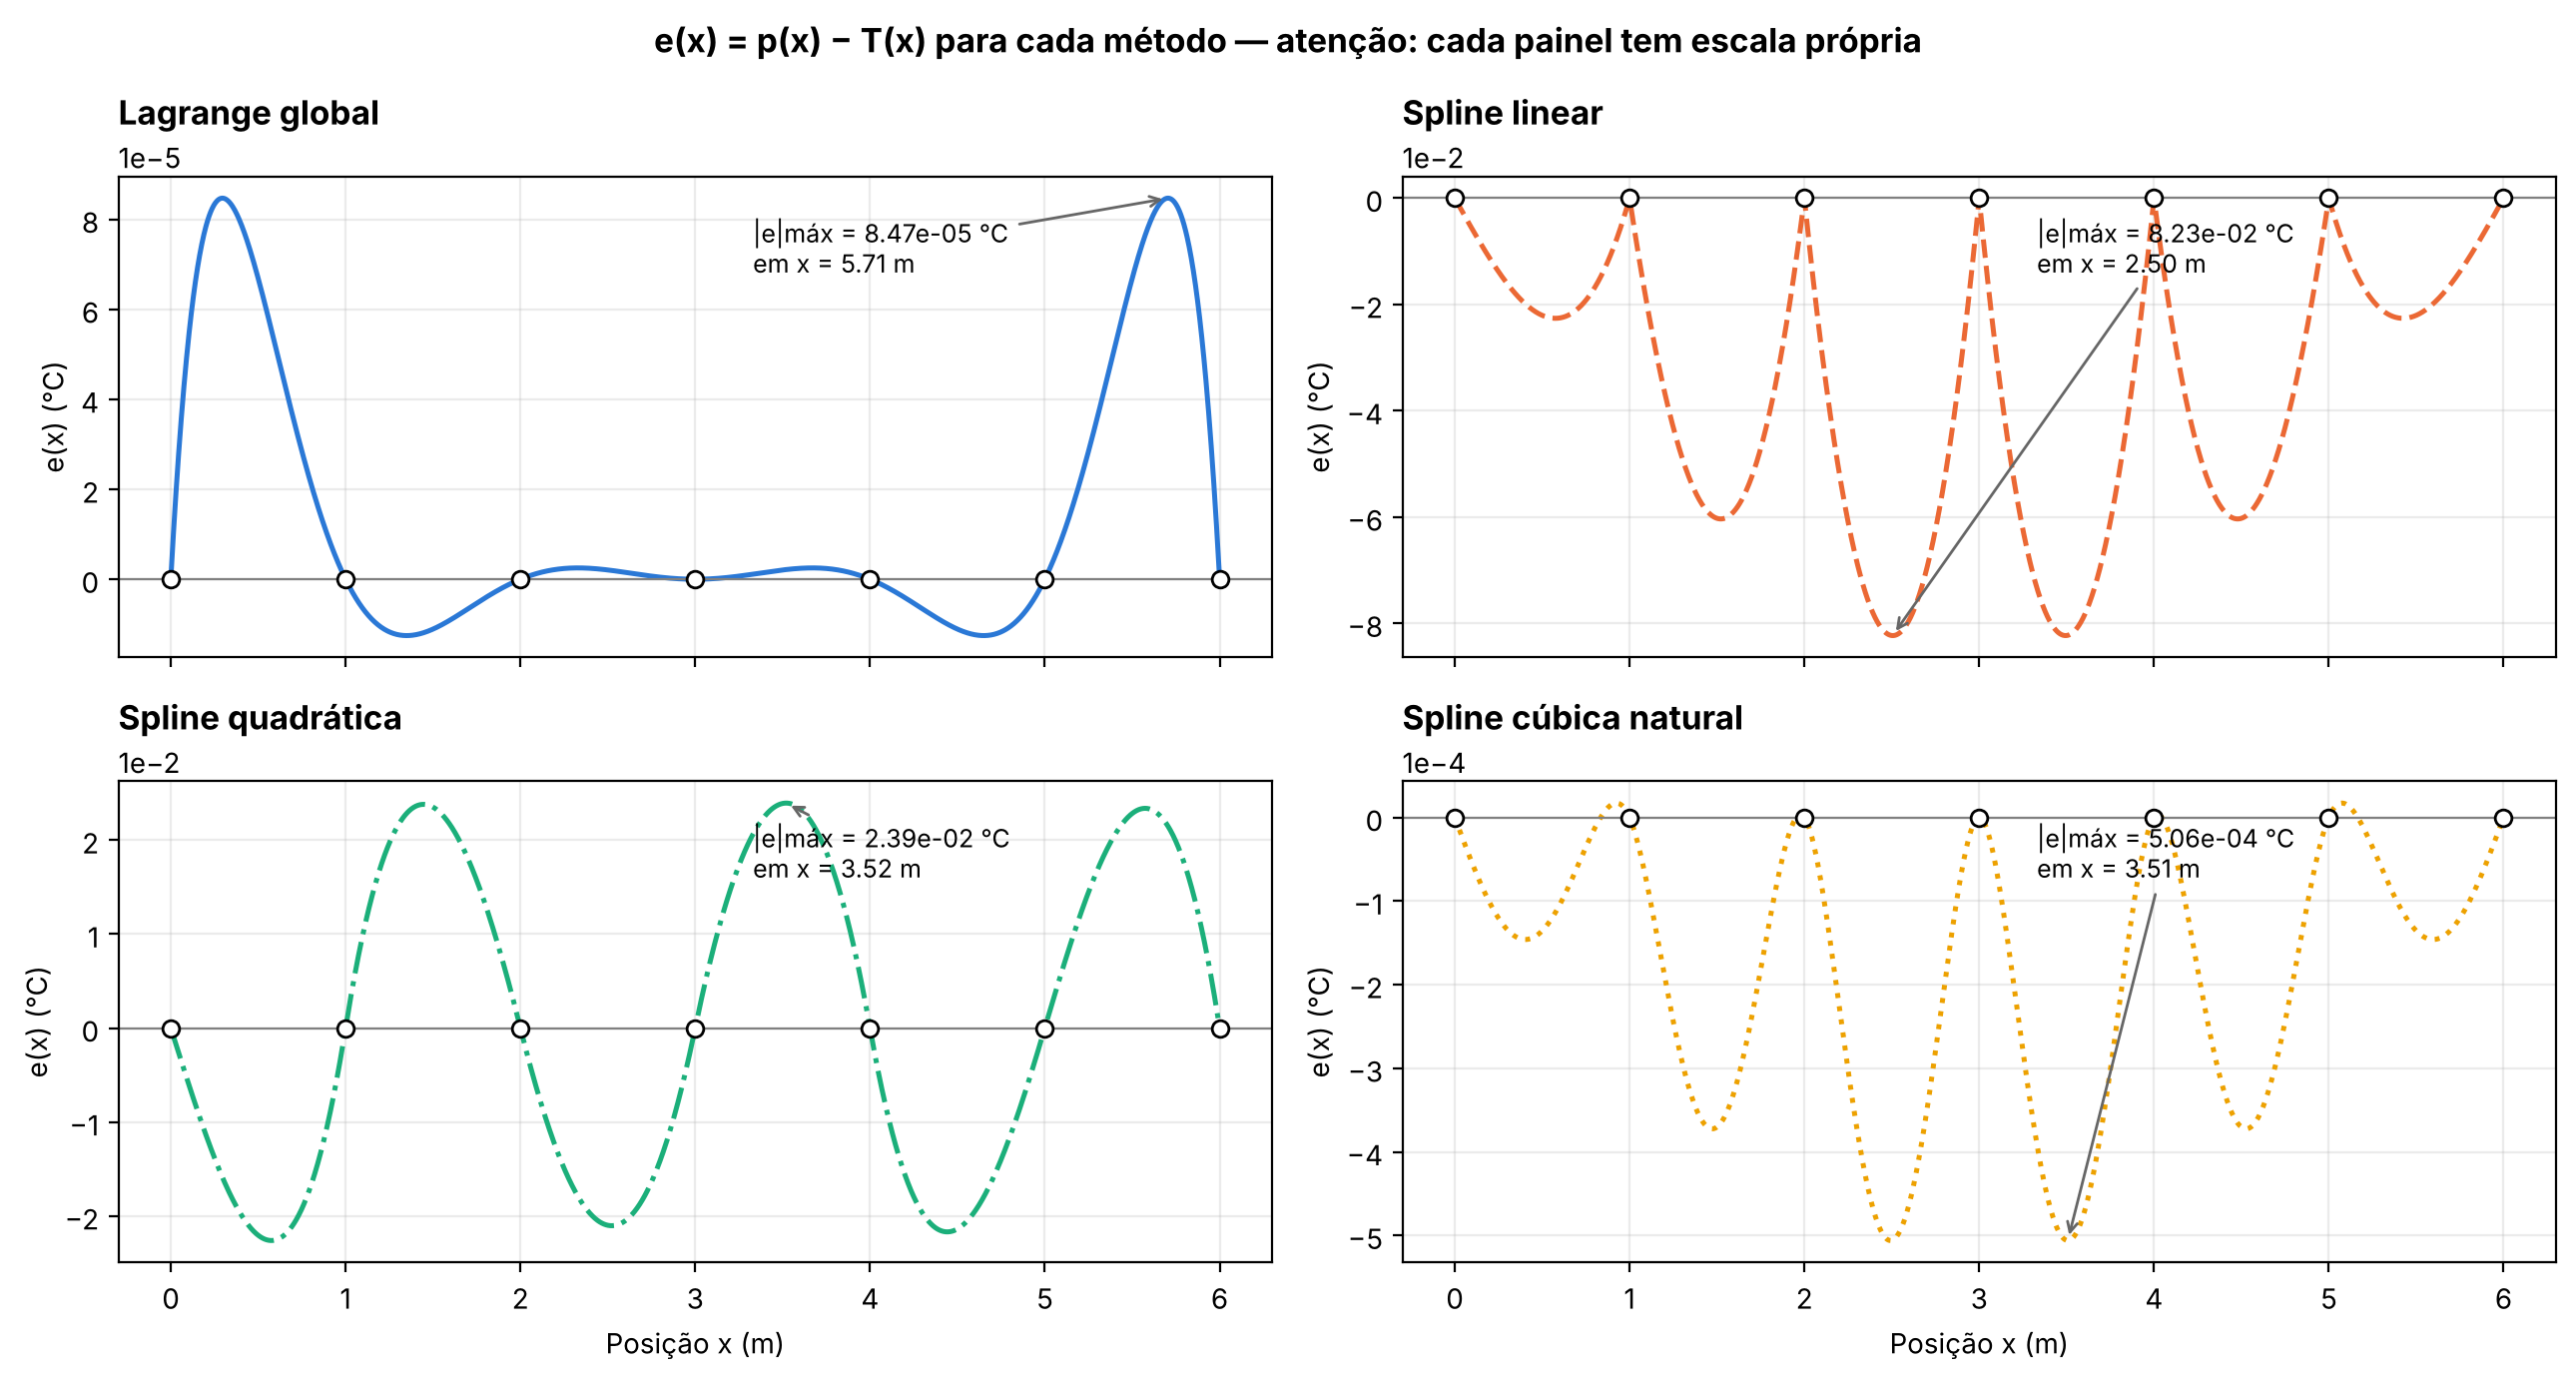

In [6]:

# Erro com sinal, e(x) = p(x) - T(x); um painel para cada método porque as ordens de grandeza diferem muito
fig, axs = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for a, (nome, f) in zip(axs.ravel(), metodos_7.items()):
    s = ESTILO[nome]
    erro = f(x_fino) - T_fino
    a.plot(x_fino, erro, color=s["color"], ls=s["ls"], lw=1.8)
    a.axhline(0, color="0.5", lw=0.8)
    a.plot(x_nos_7, np.zeros_like(x_nos_7), "o", ms=6, mfc="white", mec="black")
    i = np.argmax(np.abs(erro))
    a.annotate(f"|e|máx = {abs(erro[i]):.2e} °C\nem x = {x_fino[i]:.2f} m",
               xy=(x_fino[i], erro[i]), xytext=(0.55, 0.80), textcoords="axes fraction",
               fontsize=9, arrowprops=dict(arrowstyle="->", color="0.4"))
    a.ticklabel_format(axis="y", style="sci", scilimits=(-2, 2))
    a.set_title(nome, loc="left", weight="bold"); a.grid(alpha=0.25)
    a.set_ylabel("e(x) (°C)")
for a in axs[1]: a.set_xlabel("Posição x (m)")
fig.suptitle("e(x) = p(x) − T(x) para cada método — atenção: cada painel tem escala própria", weight="bold")
plt.tight_layout(); plt.show()


### Análise dos resultados — Etapa 1

Com sete sensores ideais igualmente espaçados, o polinômio global de Lagrange foi o método mais preciso, com RMSE de aproximadamente 3,3×10⁻⁵ °C e erro máximo de 8,5×10⁻⁵ °C. Em seguida veio a spline cúbica natural (RMSE de 2,4×10⁻⁴ °C), depois a spline quadrática (1,6×10⁻² °C) e, por último, a spline linear (4,4×10⁻² °C). Entre o melhor e o pior método há uma diferença de mais de três ordens de grandeza. Isso mostra que, mesmo com os mesmos sete pontos, a escolha da técnica de reconstrução muda completamente a qualidade da estimativa.

O desempenho do polinômio global se explica pela natureza da função de referência. O perfil $T(x)=18+2{,}4\xi+2{,}5\sin(\pi\xi)$ é formado por uma reta e uma senoide, de modo que todas as suas derivadas existem e são limitadas por $|T^{(k)}|\le 2{,}5\,(\pi/L)^k$. Na expressão do erro de interpolação,
$$e(x)=\frac{T^{(n+1)}(\eta)}{(n+1)!}\prod_{i=0}^{n}(x-x_i),$$
o fator $(\pi/L)^{n+1}/(n+1)!$ diminui muito rapidamente, porque $\pi/L\approx0{,}52$ é menor que a unidade e o fatorial cresce mais depressa que qualquer potência. Por isso um polinômio de grau 6 já é suficiente para reproduzir o perfil com erro da ordem de 10⁻⁵ °C. O gráfico de erros também mostra que os maiores desvios do Lagrange aparecem perto das extremidades, em torno de 0,3 m e 5,7 m. Essa é a região onde o produtório $\prod(x-x_i)$ assume seus maiores valores, já que ali o ponto avaliado fica distante da maioria dos nós.

A spline cúbica, por sua vez, tem erro que decresce com a quarta potência do espaçamento entre sensores. Com $h=1$ m, esse comportamento resulta em desvios da ordem de 10⁻⁴ °C, coerentes com o valor medido. O resultado foi favorecido por uma coincidência que merece ser destacada. A condição de contorno "natural" impõe curvatura nula nas duas extremidades, e o perfil verdadeiro tem exatamente essa propriedade, pois $T''(x)$ é proporcional a $\sin(\pi x/L)$, que se anula em $x=0$ e $x=L$. Em outro problema, com curvatura não nula nas bordas, essa mesma condição introduziria um erro adicional perto das extremidades. Portanto, o bom desempenho observado não deve ser tomado como garantido para qualquer perfil.

A spline quadrática apresentou um comportamento que revela uma fragilidade da sua construção. Em vez de diminuir onde a curvatura do perfil é pequena, seu erro alterna de sinal a cada intervalo com amplitude praticamente constante, próxima de 2×10⁻² °C. Esse padrão vem da condição adicional $c_0=0$, que fixa de forma arbitrária a curvatura do primeiro trecho. Como cada trecho herda a inclinação do anterior, essa escolha inicial se propaga ao longo de toda a barra. O erro, nesse caso, é mais um artefato do método do que uma consequência da função interpolada.

A spline linear, por fim, comete seus maiores erros no centro da barra, próximo de 2,5 m e 3,5 m. Esse resultado era esperado, porque o erro de uma interpolação linear em um intervalo é proporcional a $h^2|T''|/8$, e a curvatura do perfil é máxima justamente na região central. Vale lembrar que todos os métodos reproduzem exatamente os valores nos sensores, e é por isso que a comparação só tem significado quando feita nos pontos intermediários da malha fina.

## Etapa 2 — Número e posição dos sensores

Nesta etapa, investigue somente o polinômio global de Lagrange. A interpolação polinomial global pode oscilar entre nós, sobretudo perto das extremidades, quando se usam muitos nós equiespaçados. A distribuição de Chebyshev concentra nós nas bordas e pode reduzir esse efeito.

Para $N$ nós de Chebyshev-Lobatto em $[a,b]$, use

$$x_k=\frac{a+b}{2}+\frac{b-a}{2}\cos\left(\frac{k\pi}{N-1}\right),\quad k=0,\ldots,N-1.$$

Ordene as posições crescentemente. Compare $N=5,9,13,17$ para nós equiespaçados e de Chebyshev. Para cada caso, avalie o erro em todos os pontos da malha fina e registre o erro máximo e o RMSE.

**Atenção:** uma redução de erro neste perfil particular não prova que o mesmo ocorrerá para qualquer função. Relacione a observação à suavidade e à estrutura do perfil usado.

In [7]:

def nos_chebyshev_lobatto(a, b, N):
    k = np.arange(N)
    z = np.cos(k*np.pi/(N-1))
    return np.sort((a+b)/2 + (b-a)*z/2)

def erros_lagrange(x_nos):
    """Retorna erro máximo, RMSE e o vetor de erros do Lagrange baricêntrico."""
    p = BarycentricInterpolator(x_nos, temperatura_real(x_nos))
    e = p(x_fino) - T_fino
    return np.max(np.abs(e)), np.sqrt(np.mean(e**2)), e

linhas, erros_N = [], {}
for N in [5, 9, 13, 17]:
    for dist, gerador in [("Equiespaçados", lambda N: np.linspace(x_min, x_max, N)),
                          ("Chebyshev-Lobatto", lambda N: nos_chebyshev_lobatto(x_min, x_max, N))]:
        emax, rmse, e = erros_lagrange(gerador(N))
        erros_N[(N, dist)] = e
        linhas.append({"N": N, "Distribuição": dist, "Erro máximo (°C)": emax, "RMSE (°C)": rmse})

tabela_nos = pd.DataFrame(linhas)
display(tabela_nos.style.format({"Erro máximo (°C)": "{:.2e}", "RMSE (°C)": "{:.2e}"}))

# Quantas vezes o erro equiespaçado supera o de Chebyshev
piv = tabela_nos.pivot(index="N", columns="Distribuição", values="Erro máximo (°C)")
piv["Razão Emax (equi/Cheb)"] = piv["Equiespaçados"] / piv["Chebyshev-Lobatto"]
display(piv.style.format("{:.2e}", subset=["Chebyshev-Lobatto", "Equiespaçados"])
           .format("{:.1f}", subset=["Razão Emax (equi/Cheb)"]))


,N,Distribuição,Erro máximo (°C),RMSE (°C)
0,5,Equiespaçados,4.53e-03,2.16e-03
1,5,Chebyshev-Lobatto,2.33e-03,1.53e-03
2,9,Equiespaçados,1.04e-06,3.44e-07
3,9,Chebyshev-Lobatto,2.17e-07,1.20e-07
4,13,Equiespaçados,5.91e-11,1.55e-11
5,13,Chebyshev-Lobatto,3.62e-12,1.93e-12
6,17,Equiespaçados,1.99e-12,2.45e-13
7,17,Chebyshev-Lobatto,1.42e-14,3.76e-15


Distribuição,Chebyshev-Lobatto,Equiespaçados,Razão Emax (equi/Cheb)
N,,,
5,2.33e-03,4.53e-03,1.9
9,2.17e-07,1.04e-06,4.8
13,3.62e-12,5.91e-11,16.3
17,1.42e-14,1.99e-12,140.0


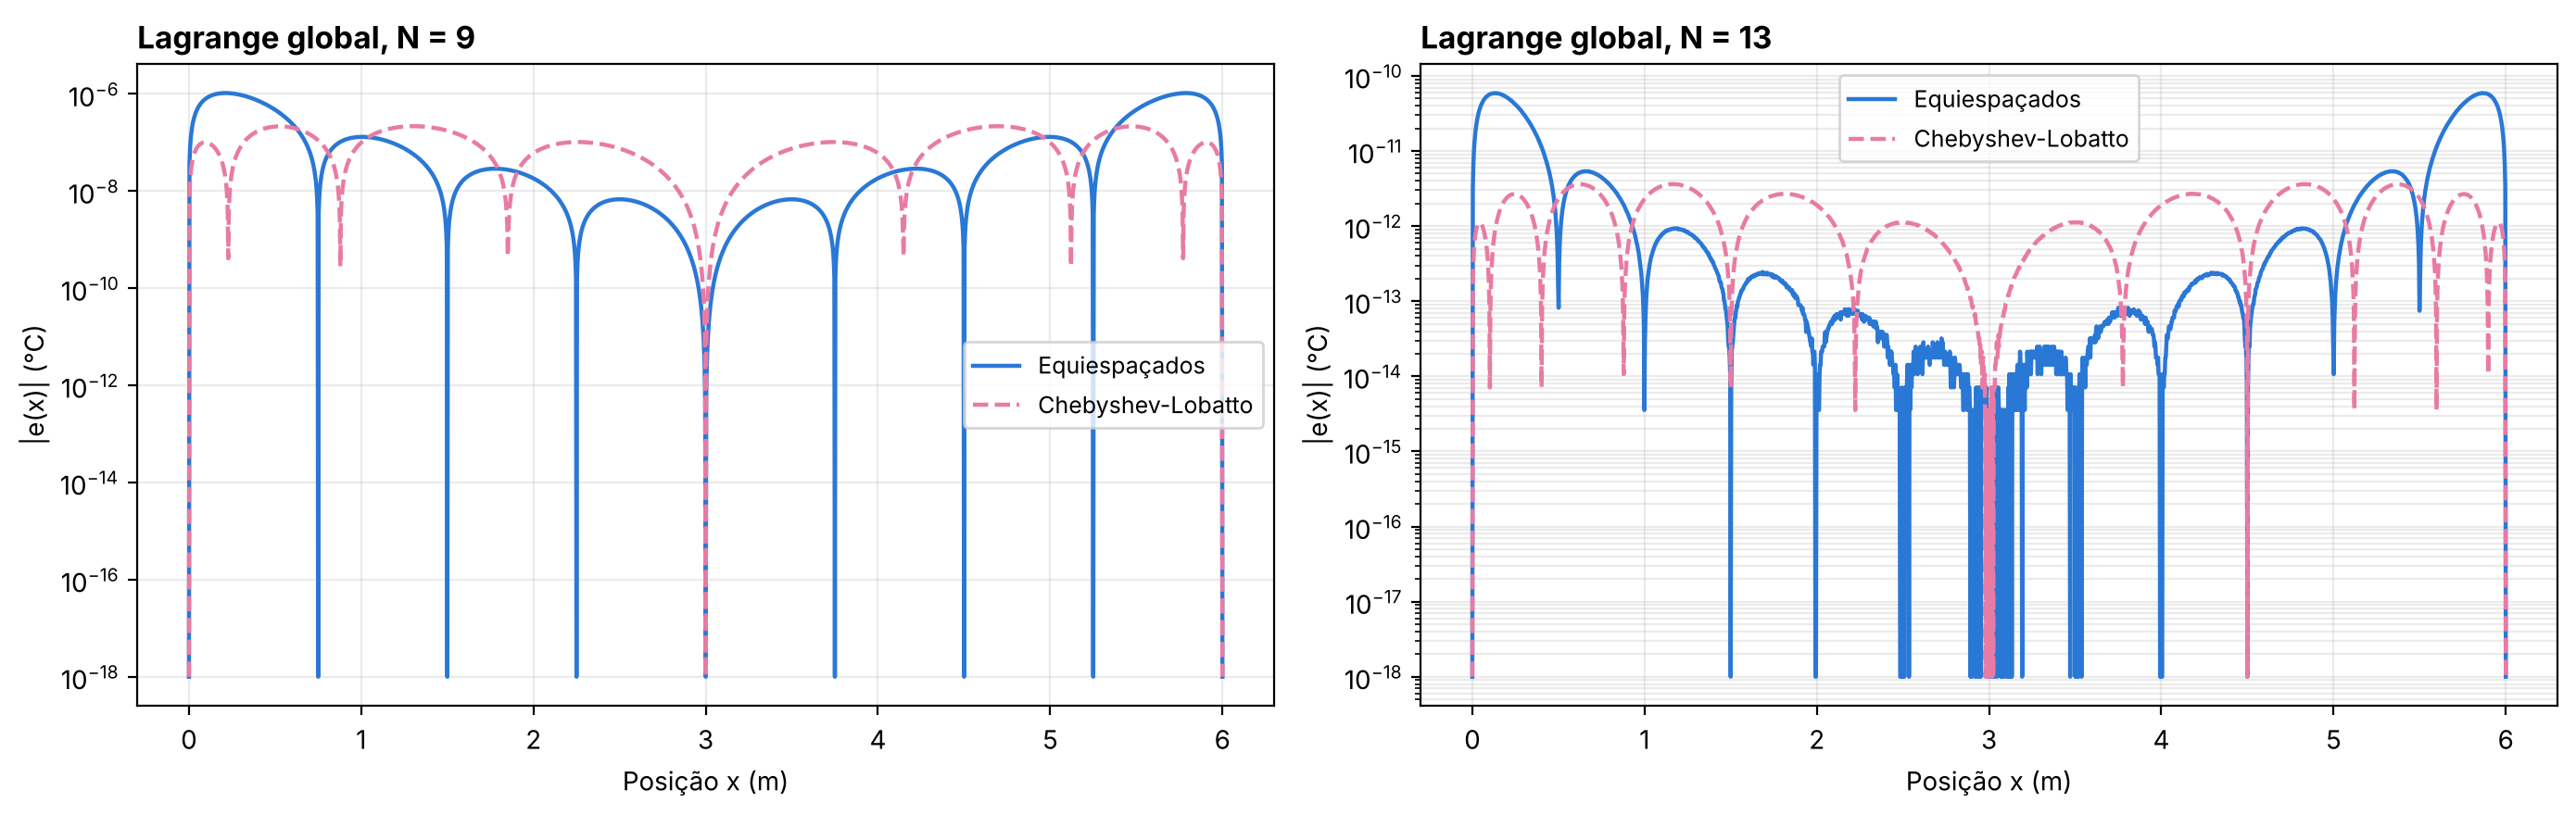

In [8]:
# Distribuição espacial do erro (escala log) para dois valores de N
fig, axs = plt.subplots(1, 2, figsize=(14, 4.5), sharey=False)
for a, N in zip(axs, [9, 13]):
    for dist, cor, ls in [("Equiespaçados", "#2a78d6", "-"), ("Chebyshev-Lobatto", "#e87ba4", "--")]:
        a.semilogy(x_fino, np.abs(erros_N[(N, dist)]) + 1e-18, color=cor, ls=ls, lw=1.6, label=dist)
    a.set_title(f"Lagrange global, N = {N}", loc="left", weight="bold")
    a.set_xlabel("Posição x (m)"); a.set_ylabel("|e(x)| (°C)"); a.grid(alpha=0.25, which="both")
    a.legend(fontsize=9)
plt.tight_layout(); plt.show()

### Análise dos resultados — Etapa 2

O aumento do número de sensores reduziu drasticamente o erro do polinômio de Lagrange nas duas distribuições testadas. Passando de 5 para 17 nós, o erro máximo caiu de cerca de 10⁻³ °C para aproximadamente 10⁻¹² °C com nós equiespaçados e 10⁻¹⁴ °C com nós de Chebyshev. Uma queda dessa magnitude, em que cada pequeno acréscimo de nós elimina várias ordens de grandeza do erro, caracteriza a chamada convergência espectral, ou exponencial. Ela é típica de funções muito suaves, como a senoide usada aqui.

Em todos os valores de N, os nós de Chebyshev produziram erros menores que os nós equiespaçados, e essa vantagem aumentou com o número de sensores. Em N = 5 o erro equiespaçado foi cerca de duas vezes maior. Em N = 9 a razão chegou a aproximadamente cinco, em N = 13 a cerca de dezesseis, e em N = 17 ultrapassou cem. Neste último caso o valor exato oscila de uma execução para outra, porque o erro de Chebyshev já está no limite da precisão numérica do computador.

O gráfico de $|e(x)|$ em escala logarítmica ajuda a entender a origem dessa diferença. Com nós uniformes, o erro se concentra perto das extremidades da barra, onde o produtório $\prod(x-x_i)$ é maior. A distribuição de Chebyshev aproxima os nós justamente nas bordas, o que reduz esse produtório onde ele seria crítico e distribui o erro de modo mais uniforme ao longo do comprimento. A vantagem de Chebyshev, portanto, não é casual: decorre diretamente da estrutura da fórmula do erro.

É importante, contudo, não generalizar a observação além do que ela permite. Neste perfil, o espaçamento uniforme também converge, e não aparece o fenômeno de Runge, em que as oscilações nas bordas crescem indefinidamente com N. Isso ocorre porque a senoide não possui singularidades no plano complexo e varia lentamente em relação ao comprimento da barra. Se o perfil tivesse, por exemplo, um pico estreito provocado por uma fonte de calor concentrada, seu comportamento seria semelhante ao da função clássica $1/(1+25x^2)$, e o polinômio com nós equiespaçados passaria a divergir à medida que mais sensores fossem adicionados. A conclusão de que Chebyshev é preferível tem validade ampla. Já a constatação de que nós uniformes também funcionam depende da suavidade particular deste perfil.

Por fim, em N = 17 o erro com nós equiespaçados ficou cerca de cem vezes acima do limite de arredondamento já alcançado por Chebyshev. Essa diferença é o primeiro indício de um problema de estabilidade numérica que a Etapa 3 torna evidente.

## Etapa 3 — Estudo de caso e decisão técnica

Faça $N$ variar de 4 a 40. Compare erro máximo e RMSE em escala logarítmica para Lagrange equiespaçado, Lagrange com Chebyshev e spline cúbica natural. Registre o tempo de construção e de avaliação. Discuta o custo e a estabilidade numérica. Para o perfil suave escolhido, haverá necessariamente um único método superior para todo $N$?

In [9]:
def cronometrar(fn, repeticoes=15):
    """Mediana do tempo de execução de fn(), em segundos."""
    t = []
    for _ in range(repeticoes):
        t0 = time.perf_counter(); fn(); t.append(time.perf_counter() - t0)
    return np.median(t)

def constante_lebesgue(x_nos, x_aval=x_fino):
    """Constante de Lebesgue: quanto uma perturbação nos dados pode ser ampliada no interpolador."""
    soma = np.zeros_like(x_aval)
    for j in range(len(x_nos)):
        yj = np.zeros(len(x_nos)); yj[j] = 1.0
        soma += np.abs(BarycentricInterpolator(x_nos, yj)(x_aval))
    return soma.max()

construtores = {
    "Lagrange equiespaçado": (lambda N: np.linspace(x_min, x_max, N),
                              lambda x, y: BarycentricInterpolator(x, y)),
    "Lagrange Chebyshev":    (lambda N: nos_chebyshev_lobatto(x_min, x_max, N),
                              lambda x, y: BarycentricInterpolator(x, y)),
    "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N),
                              lambda x, y: CubicSpline(x, y, bc_type="natural")),
}

linhas = []
for N in range(4, 41):
    for nome, (gerar_nos, construir) in construtores.items():
        x = gerar_nos(N); y = temperatura_real(x)
        f = construir(x, y)
        e = f(x_fino) - T_fino
        linhas.append({"N": N, "Método": nome,
                       "Emax": np.max(np.abs(e)), "RMSE": np.sqrt(np.mean(e**2)),
                       "t_construcao (ms)": 1e3*cronometrar(lambda: construir(x, y)),
                       "t_avaliacao (ms)":  1e3*cronometrar(lambda: f(x_fino)),
                       "Lebesgue": constante_lebesgue(x) if nome.startswith("Lagrange") else np.nan})
estudo = pd.DataFrame(linhas)

# Tabela compacta com alguns N representativos
resumo = estudo[estudo.N.isin([4, 8, 12, 16, 20, 30, 40])].pivot(index="N", columns="Método", values="Emax")
display(resumo.style.format("{:.1e}").set_caption("Erro máximo (°C) para N representativos"))

Método,Lagrange Chebyshev,Lagrange equiespaçado,Spline cúbica natural
N,,,
4,1.4e-01,1.1e-01,1.0e-02
8,3.4e-05,6.1e-05,2.8e-04
12,1.1e-09,6.6e-09,4.4e-05
16,1.8e-14,1.5e-12,1.3e-05
20,1.4e-14,1.2e-11,4.9e-06
30,1.4e-14,1.0e-08,9.0e-07
40,1.8e-14,7.3e-06,2.7e-07


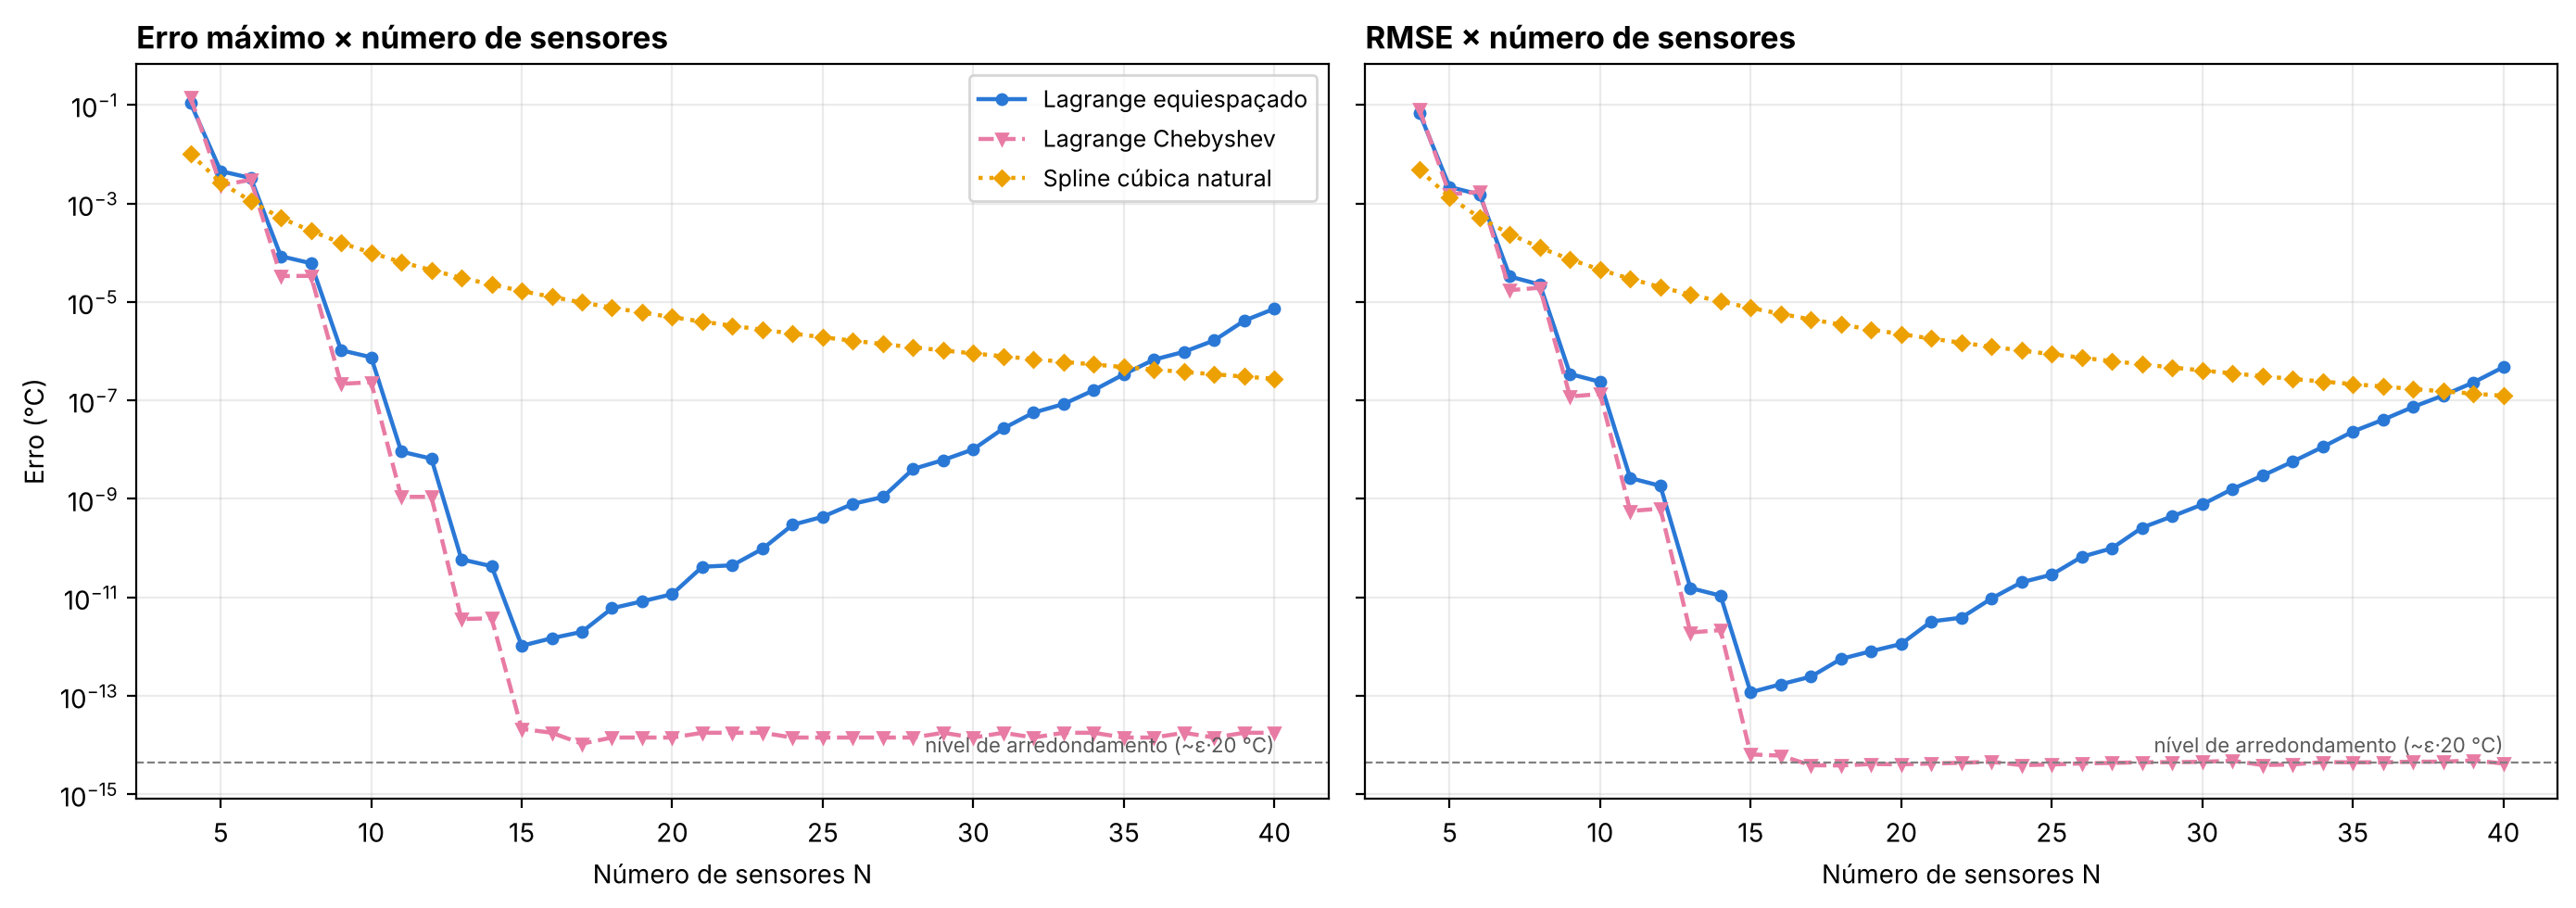

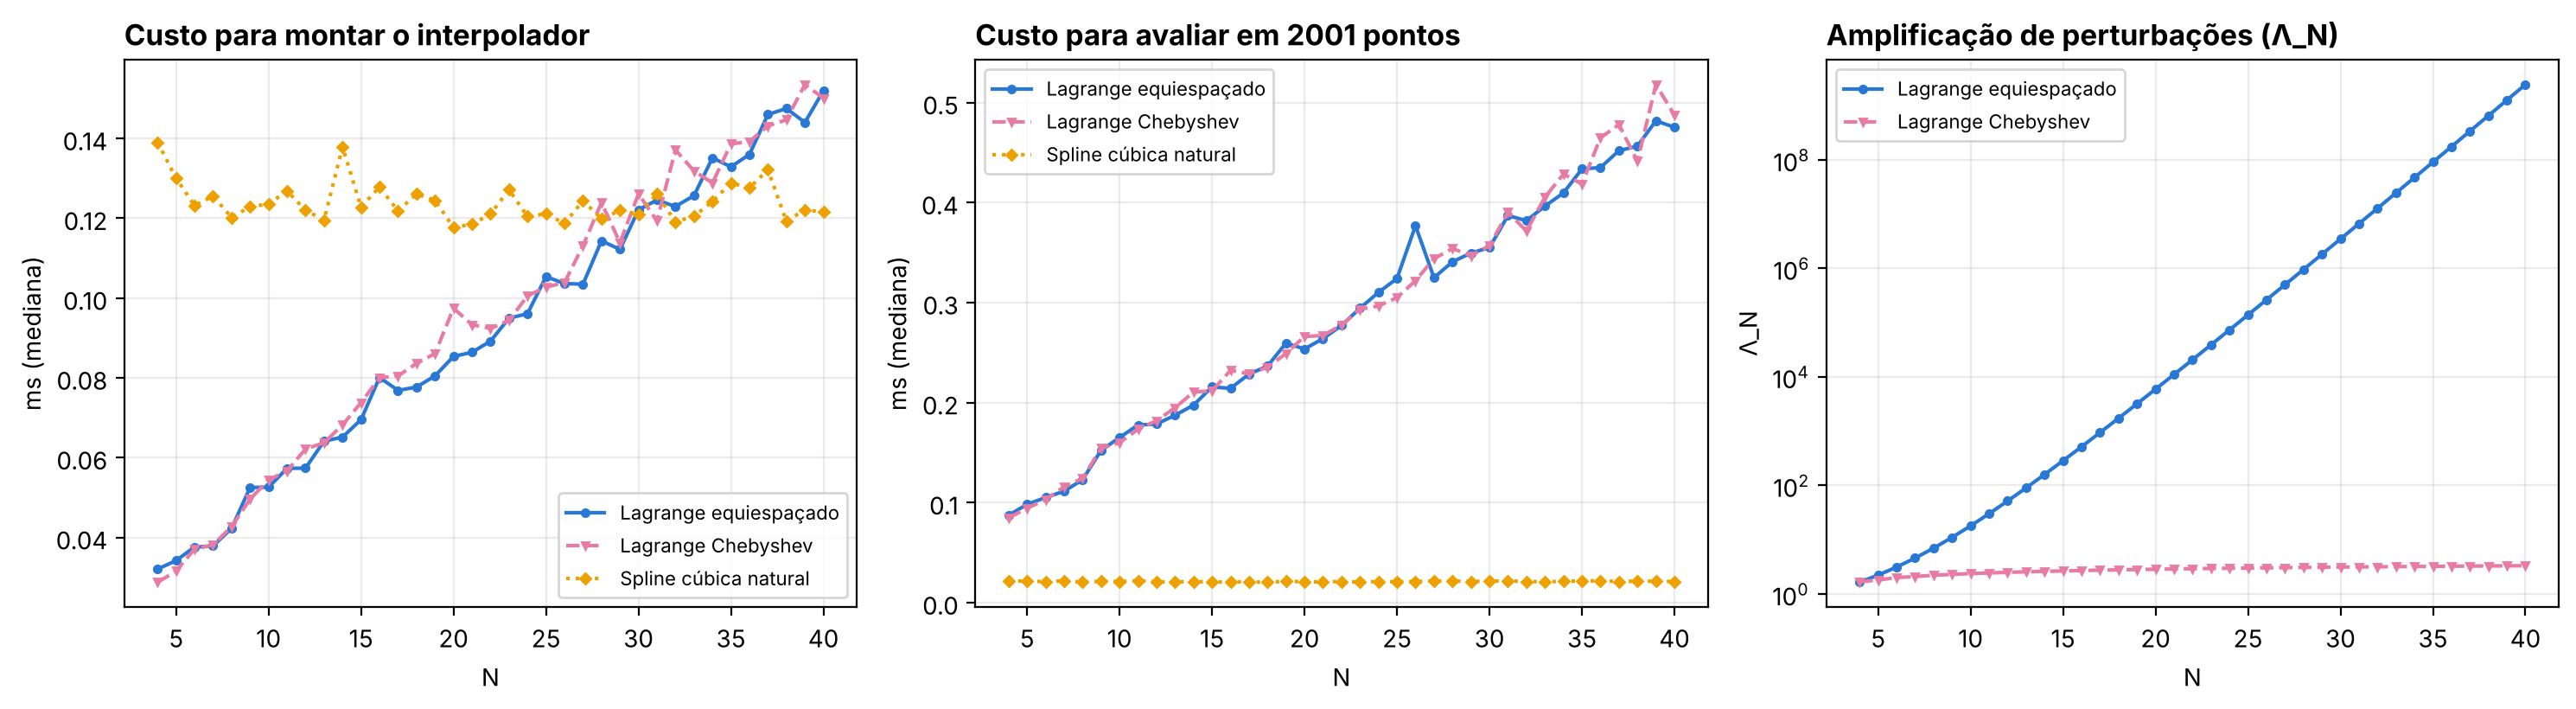

Vencedor em erro máximo para cada N:
  Lagrange Chebyshev      : N = [5, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40]
  Spline cúbica natural   : N = [4, 6]


In [10]:
cores3 = {"Lagrange equiespaçado": ("#2a78d6", "-", "o"),
          "Lagrange Chebyshev":    ("#e87ba4", "--", "v"),
          "Spline cúbica natural": ("#eda100", ":", "D")}

fig, axs = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for a, met, titulo in [(axs[0], "Emax", "Erro máximo"), (axs[1], "RMSE", "RMSE")]:
    for nome, (cor, ls, mk) in cores3.items():
        d = estudo[estudo["Método"] == nome]
        a.semilogy(d.N, d[met], color=cor, ls=ls, marker=mk, ms=4, lw=1.6, label=nome)
    a.axhline(np.finfo(float).eps*20, color="0.5", lw=0.8, ls="--")
    a.text(40, np.finfo(float).eps*20*1.6, "nível de arredondamento (~ε·20 °C)",
           ha="right", fontsize=8, color="0.35")
    a.set_title(f"{titulo} × número de sensores", loc="left", weight="bold")
    a.set_xlabel("Número de sensores N"); a.grid(alpha=0.25, which="both")
axs[0].set_ylabel("Erro (°C)"); axs[0].legend(fontsize=9)
plt.tight_layout(); plt.show()

# Custo computacional e condicionamento, cada grandeza em seu próprio eixo
fig, axs = plt.subplots(1, 3, figsize=(15, 4.2))
for nome, (cor, ls, mk) in cores3.items():
    d = estudo[estudo["Método"] == nome]
    axs[0].plot(d.N, d["t_construcao (ms)"], color=cor, ls=ls, marker=mk, ms=3, label=nome)
    axs[1].plot(d.N, d["t_avaliacao (ms)"],  color=cor, ls=ls, marker=mk, ms=3, label=nome)
    if nome.startswith("Lagrange"):
        axs[2].semilogy(d.N, d["Lebesgue"], color=cor, ls=ls, marker=mk, ms=3, label=nome)
axs[0].set_title("Custo para montar o interpolador", loc="left", weight="bold"); axs[0].set_ylabel("ms (mediana)")
axs[1].set_title("Custo para avaliar em 2001 pontos", loc="left", weight="bold"); axs[1].set_ylabel("ms (mediana)")
axs[2].set_title("Amplificação de perturbações (Λ_N)", loc="left", weight="bold"); axs[2].set_ylabel("Λ_N")
for a in axs: a.set_xlabel("N"); a.grid(alpha=0.25, which="both"); a.legend(fontsize=8)
plt.tight_layout(); plt.show()

# Para cada N, qual método teve o menor erro máximo?
melhor = estudo.loc[estudo.groupby("N")["Emax"].idxmin(), ["N", "Método"]]
print("Vencedor em erro máximo para cada N:")
for metodo, grupo in melhor.groupby("Método"):
    print(f"  {metodo:24s}: N = {sorted(grupo.N.tolist())}")

### Análise dos resultados — Etapa 3

Ao variar o número de sensores de 4 a 40, os três métodos mostraram comportamentos qualitativamente distintos. O Lagrange com nós de Chebyshev teve queda rápida do erro até N ≈ 15, quando atingiu cerca de 10⁻¹⁴ °C, o limite da aritmética de dupla precisão para valores próximos de 20 °C. A partir desse ponto, o erro permaneceu estável até N = 40: não há mais como melhorar, mas o método também não se deteriora.

O Lagrange com nós equiespaçados acompanhou essa queda até atingir seu menor erro, cerca de 10⁻¹² °C em torno de N = 15. Depois disso, o erro voltou a crescer continuamente, chegando a 10⁻¹¹ °C em N = 20, 10⁻⁸ °C em N = 30 e 10⁻⁵ °C em N = 40. Esse crescimento não pode ser atribuído ao erro de aproximação, que nessa faixa já é desprezível. Ele resulta da amplificação dos erros de arredondamento, ou seja, de um problema de condicionamento numérico. A spline cúbica, por sua vez, teve redução lenta e contínua do erro, compatível com a taxa teórica $O(h^4)$, que em escala log-log corresponde a uma reta de inclinação aproximadamente −4. Ela converge muito mais devagar que o polinômio no início, mas nunca piora ao receber mais sensores.

Esses comportamentos respondem diretamente à pergunta da etapa: mesmo para um perfil suave, não existe um único método superior para todo N. A spline cúbica teve o menor erro máximo em N = 4 e em N = 6. Em N = 4 a vantagem foi de uma ordem de grandeza, porque um polinômio de grau 3 ainda não consegue representar bem a senoide. Em N = 5 e a partir de N = 7, o Lagrange com Chebyshev assumiu a liderança e não a perdeu mais. Já o Lagrange equiespaçado, que entre aproximadamente 7 e 30 sensores era muito superior à spline, teve sua curva de erro cruzada pela dela por volta de N = 35 a 40, tornando-se a pior opção. Um método excelente com dez sensores pode ser inadequado com quarenta, e a escolha depende tanto da quantidade quanto da posição dos sensores.

A explicação para a instabilidade dos nós equiespaçados está na constante de Lebesgue, $\Lambda_N=\max_x\sum_j|\ell_j(x)|$. Ela indica quanto uma perturbação nos dados pode ser ampliada no polinômio interpolador: se cada valor tiver um erro de no máximo $\delta$, o resultado pode se afastar do ideal em até $\Lambda_N\,\delta$. O terceiro painel do gráfico de custo mostra que, para os nós de Chebyshev, essa constante cresce apenas de forma logarítmica e vale cerca de 3 em N = 40. Para nós uniformes, ela cresce de forma exponencial e atinge aproximadamente 10⁹ no mesmo N. Assim, um erro de arredondamento da ordem de 10⁻¹⁵ pode ser transformado em um desvio da ordem de 10⁻⁶, exatamente o que se observa nas curvas. A forma baricêntrica é um algoritmo estável e evita erros adicionais no cálculo, mas não altera o fato de que o problema de interpolar em nós uniformes é, em si, mal condicionado. A spline cúbica, ao contrário, tem um fator de amplificação limitado, da ordem de 1 a 2, independentemente de N.

Quanto ao custo computacional, a análise teórica indica que o Lagrange baricêntrico exige $O(N^2)$ operações para calcular os pesos e $O(mN)$ para avaliar o polinômio em $m$ pontos. A spline cúbica resolve um sistema tridiagonal em $O(N)$ e avalia em $O(m\log N)$. Nas medições, os tempos de construção ficaram entre 0,03 e 0,2 ms para todos os métodos. A spline chegou a ser mais lenta para N pequeno, o que se explica pelo custo fixo das chamadas à biblioteca SciPy, que nessa escala supera a diferença de complexidade. Na avaliação a diferença ficou clara: o tempo do Lagrange cresceu linearmente com N, de cerca de 0,1 ms para 0,5 ms, enquanto o da spline permaneceu praticamente constante em 0,02 ms. Em aplicações com muitos sensores ou com avaliações frequentes, como um monitoramento contínuo, essa diferença favorece a spline. Como as medições de tempo variam entre execuções por fatores do sistema operacional, a interpretação deve se apoiar na tendência das curvas, e não em pontos isolados.

## Etapa 4 — Estudo de caso e decisão técnica

Uma equipe precisa estimar a temperatura em posições internas da barra, com sensores ruidosos. Não haverá sensores em todos os pontos e a solução verdadeira será desconhecida em campo. Com base nos experimentos, escreva uma recomendação técnica.

A recomendação deve responder:
- que método escolheria com poucos sensores exatos e por quê;
- como a recomendação muda quando se aumenta o número de sensores;
- o que faria quando os sensores apresentam ruído;
- que cuidados adotaria perto das extremidades;
- que limitações permanecem quando a temperatura verdadeira não é conhecida.

Use pelo menos duas métricas da atividade. Diferencie interpolação dentro do intervalo medido de extrapolação além dele.

### Experimento extra 1 — sensores com ruído

A Etapa 4 pede uma recomendação para sensores ruidosos, mas as etapas anteriores trabalharam apenas com dados exatos. Para que a recomendação tivesse base experimental, simulamos leituras perturbadas por um erro aleatório gaussiano com desvio-padrão de 0,1 °C. Essa ordem de grandeza é compatível com termopares e termistores de uso comum. Testamos 7, 13 e 25 sensores. Como um único sorteio de ruído poderia produzir um resultado excepcionalmente bom ou ruim, repetimos o procedimento 300 vezes e calculamos as médias das métricas, segundo o método de Monte Carlo. Em todos os casos, o erro foi medido em relação ao perfil verdadeiro, e não às leituras ruidosas, porque o interesse está em saber quão perto da temperatura real cada método consegue chegar.

Além dos interpoladores já estudados, incluímos uma spline de suavização, implementada pela função `make_smoothing_spline` do SciPy. Diferentemente dos demais métodos, ela não é obrigada a passar pelos pontos medidos. Ela busca uma curva que permaneça próxima das leituras sem se curvar excessivamente, e o equilíbrio entre essas duas exigências é escolhido automaticamente por validação cruzada generalizada. Do ponto de vista técnico, trata-se de um ajuste de curva, e não de uma interpolação, e essa distinção é justamente o que o experimento procura avaliar.

In [11]:
from scipy.interpolate import make_smoothing_spline

sigma = 0.10          # incerteza (1 desvio-padrão) de cada sensor, em °C
n_rep = 300           # número de sorteios independentes de ruído
rng = np.random.default_rng(2026)

metodos_ruido = {
    "Lagrange global":       (lambda N: np.linspace(x_min, x_max, N), lambda x, y: BarycentricInterpolator(x, y)),
    "Lagrange Chebyshev":    (lambda N: nos_chebyshev_lobatto(x_min, x_max, N), lambda x, y: BarycentricInterpolator(x, y)),
    "Spline cúbica natural": (lambda N: np.linspace(x_min, x_max, N), lambda x, y: CubicSpline(x, y, bc_type="natural")),
    "Spline de suavização":  (lambda N: np.linspace(x_min, x_max, N), lambda x, y: make_smoothing_spline(x, y)),
}

linhas = []
for N in [7, 13, 25]:
    acum = {nome: {"Emax": [], "RMSE": []} for nome in metodos_ruido}
    for _ in range(n_rep):
        for nome, (gerar_nos, construir) in metodos_ruido.items():
            x = gerar_nos(N)
            y = temperatura_real(x) + rng.normal(0, sigma, N)   # leitura = valor real + ruído
            e = construir(x, y)(x_fino) - T_fino                 # comparação sempre com o perfil real
            acum[nome]["Emax"].append(np.max(np.abs(e)))
            acum[nome]["RMSE"].append(np.sqrt(np.mean(e**2)))
    for nome, d in acum.items():
        linhas.append({"N": N, "Método": nome,
                       "Emax médio (°C)": np.mean(d["Emax"]),
                       "RMSE médio (°C)": np.mean(d["RMSE"]),
                       "RMSE p95 (°C)":   np.percentile(d["RMSE"], 95)})
tabela_ruido = pd.DataFrame(linhas)
display(tabela_ruido.pivot(index="Método", columns="N", values="RMSE médio (°C)")
        .style.format("{:.3g}").set_caption(f"RMSE médio contra T verdadeira (σ = {sigma} °C, {n_rep} realizações)"))
display(tabela_ruido.pivot(index="Método", columns="N", values="Emax médio (°C)")
        .style.format("{:.3g}").set_caption("Erro máximo médio (°C)"))

N,7,13,25
Método,,,
Lagrange Chebyshev,0.0913,0.0962,0.0963
Lagrange global,0.118,0.787,680
Spline cúbica natural,0.0913,0.0913,0.0938
Spline de suavização,0.0788,0.0611,0.0445


N,7,13,25
Método,,,
Lagrange Chebyshev,0.181,0.215,0.239
Lagrange global,0.256,3.33,4.25e+03
Spline cúbica natural,0.182,0.207,0.237
Spline de suavização,0.156,0.134,0.104


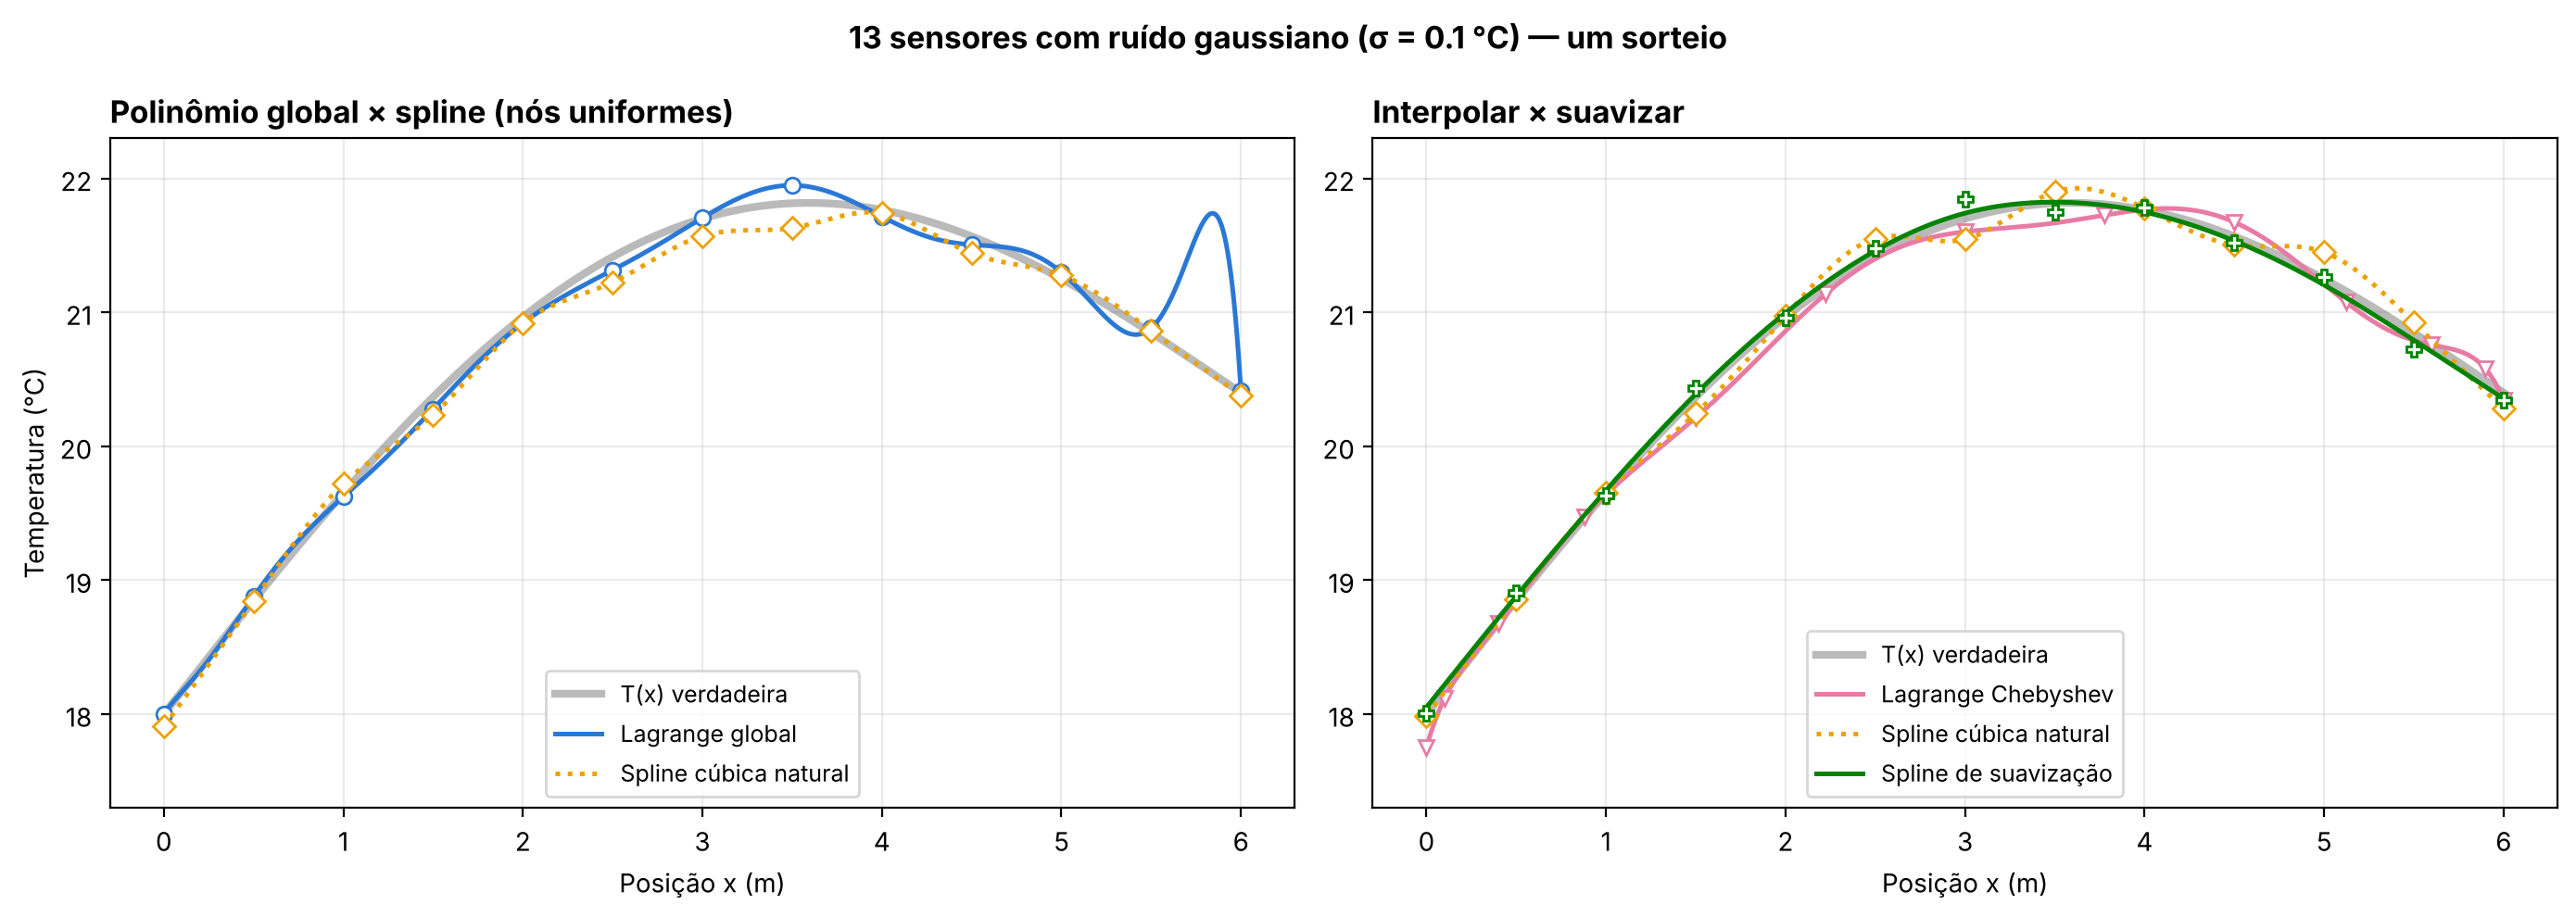

In [12]:
# Exemplo visual: um único sorteio de ruído com 13 sensores
rng_fig = np.random.default_rng(7)
N = 13
fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for a, nomes, titulo in [
        (axs[0], ["Lagrange global", "Spline cúbica natural"], "Polinômio global × spline (nós uniformes)"),
        (axs[1], ["Lagrange Chebyshev", "Spline cúbica natural", "Spline de suavização"], "Interpolar × suavizar")]:
    a.plot(x_fino, T_fino, color=COR_REF, lw=3, alpha=0.35, label="T(x) verdadeira")
    for nome in nomes:
        gerar_nos, construir = metodos_ruido[nome]
        x = gerar_nos(N); y = temperatura_real(x) + rng_fig.normal(0, sigma, N)
        s = ESTILO[nome]
        a.plot(x_fino, construir(x, y)(x_fino), color=s["color"], ls=s["ls"], lw=1.8, label=nome)
        a.plot(x, y, s["marker"], ms=6, mfc="white", mec=s["color"])
    a.set_ylim(17.3, 22.3); a.grid(alpha=0.25); a.set_xlabel("Posição x (m)")
    a.set_title(titulo, loc="left", weight="bold"); a.legend(fontsize=9, loc="lower center")
axs[0].set_ylabel("Temperatura (°C)")
fig.suptitle(f"{N} sensores com ruído gaussiano (σ = {sigma} °C) — um sorteio", weight="bold")
plt.tight_layout(); plt.show()

### Experimento extra 2 — ausência de sensores nas extremidades

Em uma instalação real, nem sempre é possível fixar sensores exatamente nas pontas da barra. Para avaliar as consequências dessa limitação, posicionamos sete sensores sem ruído apenas entre 0,5 m e 5,5 m e usamos os métodos para estimar a temperatura ao longo de toda a barra. Dentro desse intervalo os métodos interpolam. Nas faixas sombreadas do gráfico, abaixo de 0,5 m e acima de 5,5 m, eles extrapolam, isto é, estimam valores em uma região onde não há nenhuma medição para orientá-los.

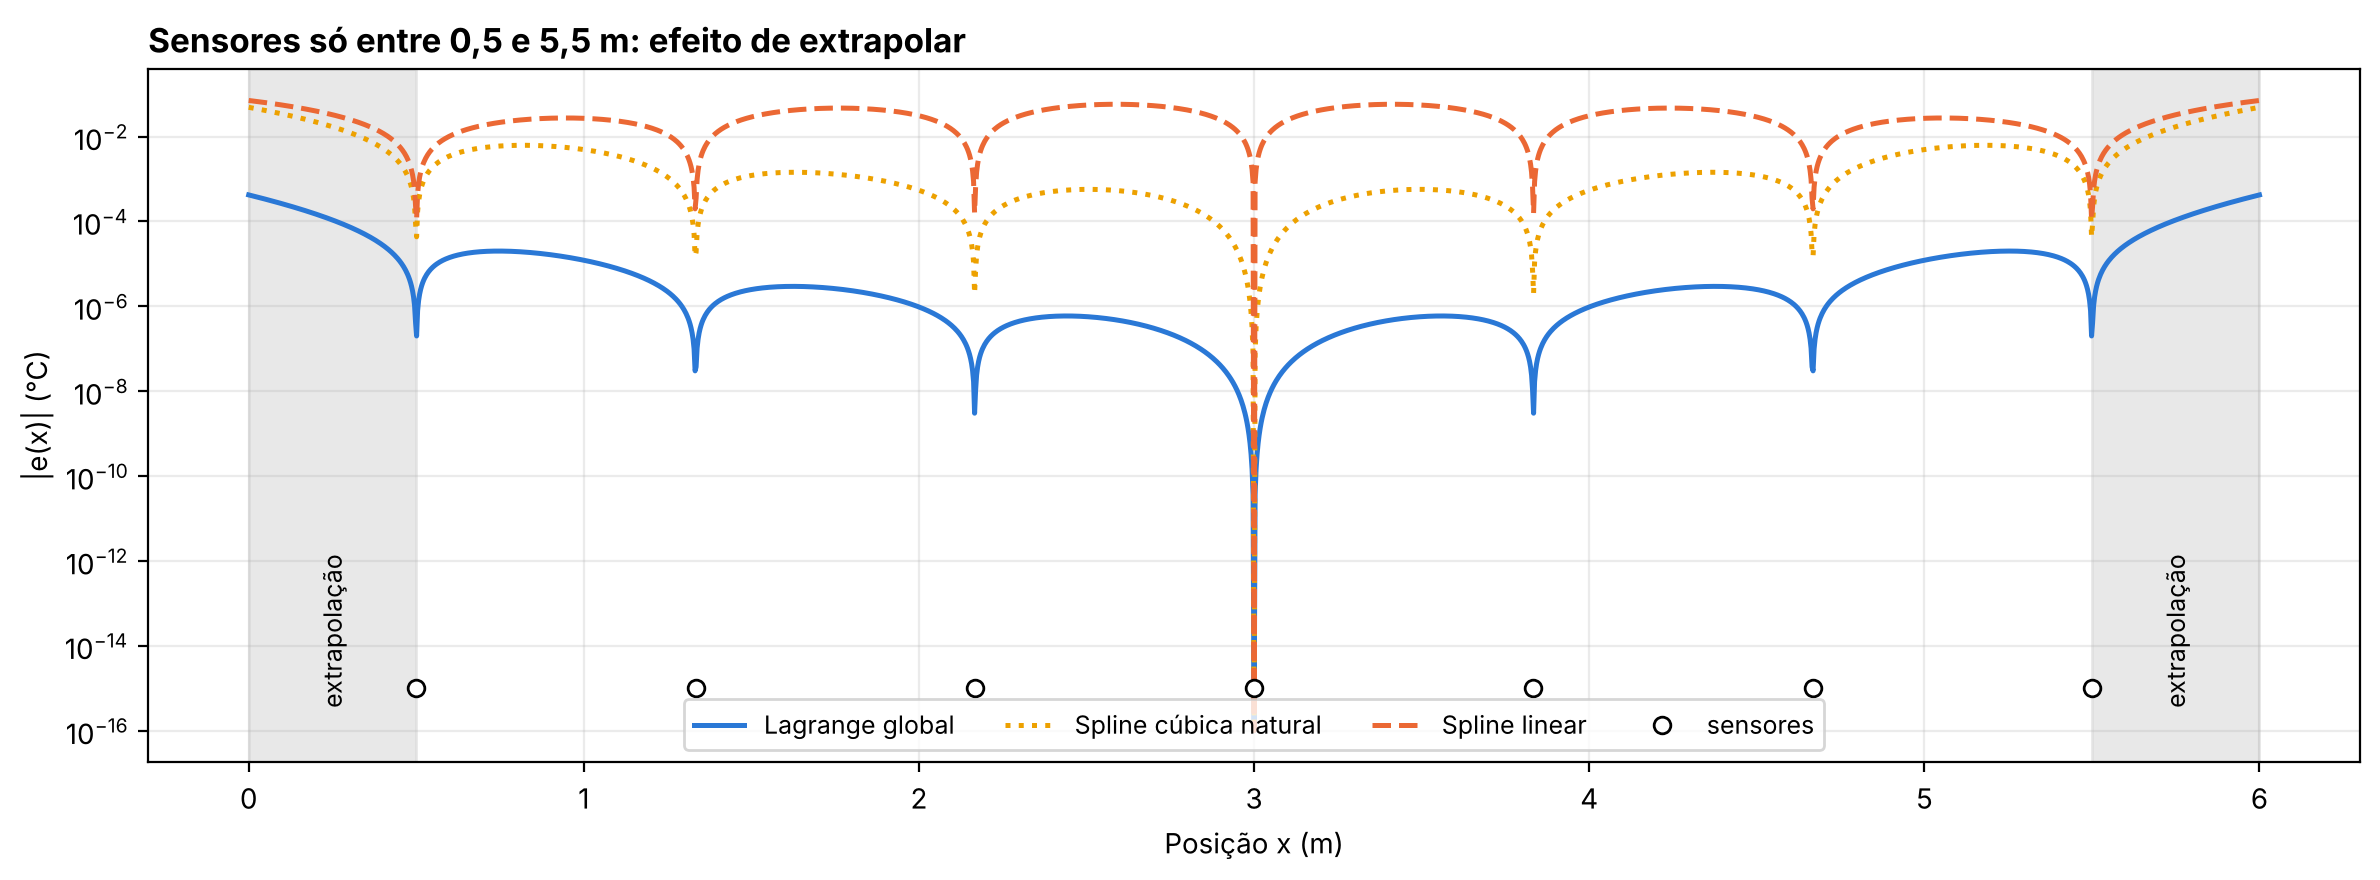

,Método,Emax interpolação (°C),Emax extrapolação (°C),Razão extrap/interp
0,Lagrange global,2.01e-05,4.23e-04,21×
1,Spline cúbica natural,6.25e-03,4.90e-02,8×
2,Spline linear,5.79e-02,7.11e-02,1×


In [13]:
x_int = np.linspace(0.5, 5.5, 7)
y_int = temperatura_real(x_int)
mets_ext = {"Lagrange global": BarycentricInterpolator(x_int, y_int),
            "Spline cúbica natural": CubicSpline(x_int, y_int, bc_type="natural", extrapolate=True),
            "Spline linear": interp1d(x_int, y_int, kind="linear", fill_value="extrapolate")}
dentro = (x_fino >= 0.5) & (x_fino <= 5.5)
linhas = []
fig, ax = plt.subplots(figsize=(12, 4.5))
ax.axvspan(0, 0.5, color="0.85", alpha=0.6); ax.axvspan(5.5, 6, color="0.85", alpha=0.6)
for nome, f in mets_ext.items():
    e = f(x_fino) - T_fino
    s = ESTILO[nome]
    ax.semilogy(x_fino, np.abs(e) + 1e-16, color=s["color"], ls=s["ls"], lw=1.8, label=nome)
    linhas.append({"Método": nome,
                   "Emax interpolação (°C)": np.max(np.abs(e[dentro])),
                   "Emax extrapolação (°C)": np.max(np.abs(e[~dentro]))})
ax.text(0.25, 0.30, "extrapolação", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, rotation=90)
ax.text(5.75, 0.30, "extrapolação", transform=ax.get_xaxis_transform(), ha="center", va="top", fontsize=9, rotation=90)
ax.plot(x_int, np.full_like(x_int, 1e-15), "o", mfc="white", mec="black", label="sensores")
ax.set_xlabel("Posição x (m)"); ax.set_ylabel("|e(x)| (°C)"); ax.grid(alpha=0.25, which="both")
ax.set_title("Sensores só entre 0,5 e 5,5 m: efeito de extrapolar", loc="left", weight="bold")
ax.legend(fontsize=9, loc="lower center", ncol=4); plt.tight_layout(); plt.show()
tab_ext = pd.DataFrame(linhas)
tab_ext["Razão extrap/interp"] = tab_ext.iloc[:, 2] / tab_ext.iloc[:, 1]
fmt = {c: "{:.2e}" for c in tab_ext.columns[1:3]}; fmt["Razão extrap/interp"] = "{:.0f}×"
display(tab_ext.style.format(fmt))

### Discussão dos experimentos extras

O primeiro resultado do experimento com ruído é que o erro de interpolação estudado nas Etapas 1 a 3 deixa de ser relevante. Com dados exatos, ele era de 10⁻⁴ °C ou menos, cerca de mil vezes menor que o ruído de 0,1 °C introduzido. A partir do momento em que as leituras são imperfeitas, o que determina a qualidade da estimativa é a forma como cada método reage ao ruído.

O polinômio de Lagrange com nós equiespaçados confirmou na prática o que a constante de Lebesgue havia indicado. Seu RMSE médio foi de 0,12 °C com 7 sensores, subiu para 0,79 °C com 13 e chegou a cerca de 680 °C com 25 sensores, com erros máximos da ordem de milhares de graus. Uma perturbação de décimos de grau foi amplificada a ponto de tornar o resultado fisicamente absurdo. Mesmo com 13 sensores, a realização mostrada no gráfico já apresenta uma oscilação espúria de cerca de um grau perto de 6 m.

O Lagrange com nós de Chebyshev e a spline cúbica mostraram-se estáveis, com RMSE entre 0,09 e 0,10 °C nos três casos. Entretanto, nenhum dos dois melhorou com o aumento do número de sensores, e a razão é conceitual. Interpolar significa obrigar a curva a passar exatamente por cada leitura, inclusive pelo erro que ela carrega. Acrescentar sensores, nesse contexto, apenas acrescenta pontos ruidosos aos quais a curva precisa obedecer, e o erro final permanece no mesmo nível do próprio ruído.

A spline de suavização foi o único método cujo erro diminuiu com mais sensores: o RMSE médio passou de 0,079 °C com 7 sensores para 0,061 °C com 13 e 0,045 °C com 25. Como ela não precisa passar pelos pontos, consegue combinar a informação de leituras vizinhas, de modo que os erros aleatórios tendem a se compensar. Esse resultado mostra que, com dados ruidosos, mais sensores só se traduzem em mais precisão quando o método é capaz de explorar a redundância entre eles.

O experimento de extrapolação, por sua vez, mostrou que avançar apenas meio metro além do último sensor já é suficiente para degradar significativamente a estimativa. O erro máximo aumentou cerca de vinte vezes no polinômio de Lagrange e cerca de oito vezes na spline cúbica. Na spline linear o aumento foi pequeno porque seu erro dentro do intervalo já era elevado, mas ela continuou sendo a opção menos precisa em valor absoluto. Fora da região medida, cada método simplesmente prolonga a última tendência que "observou", sem qualquer informação sobre o que de fato ocorre ali. No caso do polinômio de grau $n$, o desvio cresce aproximadamente com a potência $n$ da distância ao último sensor, de modo que extrapolar mais longe agravaria rapidamente o problema.

### Parecer técnico

A equipe precisa estimar a temperatura em posições internas de uma barra de 6 m a partir de sensores ruidosos, sem conhecer o perfil verdadeiro. As recomendações a seguir se baseiam em duas métricas medidas ao longo da atividade: o erro máximo, que representa o pior desvio encontrado, e o RMSE, que resume o desempenho típico e penaliza desvios grandes.

Quando há poucos sensores e eles são confiáveis, a recomendação depende da liberdade de posicionamento. Se for possível escolher as posições, convém concentrar os sensores perto das extremidades, segundo a distribuição de Chebyshev, e usar o polinômio global de Lagrange. Se as posições forem fixas e uniformes, a spline cúbica é a escolha mais adequada. Com sete sensores ideais, ambos os métodos alcançaram RMSE inferior a 10⁻³ °C, enquanto as splines linear e quadrática ficaram em 4×10⁻² °C e 2×10⁻² °C, respectivamente. A diferença entre os dois métodos recomendados é pequena e varia com o número de sensores: com apenas quatro, a spline teve erro máximo dez vezes menor que o polinômio. Por isso nenhum dos dois deve ser considerado universalmente superior.

À medida que o número de sensores aumenta, o polinômio global com espaçamento uniforme deve ser abandonado. A partir de cerca de 15 sensores, seu erro máximo passou a crescer por instabilidade numérica e, entre 35 e 40 sensores, superou o da spline cúbica. Os nós de Chebyshev mantêm a estabilidade, mas exigem posições muito específicas e concentradas nas bordas, o que raramente é viável em uma instalação real. Nesse regime, a spline cúbica é a opção mais segura, porque sua precisão melhora de forma previsível com o espaçamento, seu custo computacional é baixo e ela não está sujeita à amplificação exponencial de perturbações.

Quando os sensores apresentam ruído, que é a situação realista, a interpolação deixa de ser a abordagem adequada e deve ser substituída por um ajuste. Nenhum interpolador conseguiu RMSE abaixo do próprio nível de ruído, de aproximadamente 0,09 °C, independentemente do número de sensores, e o polinômio com nós uniformes chegou a amplificar o ruído para centenas de graus com 25 sensores. A spline de suavização, com o parâmetro de suavidade escolhido por validação cruzada, foi a única abordagem cujo erro diminuiu com mais sensores (de 0,079 °C para 0,045 °C), e por isso é a recomendação principal. Um ajuste por mínimos quadrados com poucos parâmetros, de preferência inspirado no modelo físico, como $T\approx a+bx+c\sin(\pi x/L)$, é uma alternativa igualmente defensável. Em qualquer caso, a estimativa deve ser apresentada com uma faixa de incerteza, obtida a partir da calibração dos sensores, da repetição de leituras e da propagação do ruído por métodos como Monte Carlo ou bootstrap.

As extremidades da barra merecem atenção especial, pois foram a região mais sensível em todos os experimentos. É ali que o polinômio com nós uniformes oscila e que a escolha da condição de contorno da spline faz mais diferença. Recomenda-se sempre instalar sensores nas duas pontas ou, alternativamente, incorporar as temperaturas prescritas $T(0)$ e $T(L)$ como dados. A condição de contorno da spline também deve ser escolhida com base na física do problema, e não por hábito. A condição natural funcionou bem neste estudo porque a curvatura real é nula nas extremidades. Se houver troca de calor ou fonte térmica perto das bordas, essa hipótese deixa de valer, e condições como *not-a-knot* ou a imposição da derivada, quando o fluxo $-k\,dT/dx$ for conhecido, tornam-se mais apropriadas.

É fundamental distinguir interpolação de extrapolação. Estimativas entre o primeiro e o último sensor são interpolações, e as métricas deste estudo dão uma medida razoável de sua confiabilidade. Estimativas fora desse intervalo são extrapolações, e o experimento mostrou que bastou meio metro para multiplicar o erro máximo por oito a vinte vezes. Valores extrapolados não devem ser apresentados como medições. Quando forem indispensáveis, devem ser identificados como estimativas de modelo e, preferencialmente, obtidos a partir da física do problema, como as condições de contorno e a equação de condução, e não do interpolador.

Por fim, algumas limitações permanecem quando a temperatura verdadeira é desconhecida. As métricas usadas neste estudo dependem da resposta exata e, portanto, não podem ser calculadas em campo. Uma alternativa é a validação cruzada do tipo *leave-one-out*, em que cada sensor é retirado, seu valor é previsto pelos demais e o procedimento se repete para todos. Outra é a instalação de sensores de controle que não participam do ajuste. A estimativa teórica do erro de interpolação também não é aplicável diretamente, pois depende de derivadas de $T$ que não são conhecidas. A própria suavidade do perfil é uma hipótese: variações bruscas, causadas por fontes localizadas, juntas ou mudanças de material, exigiriam mais sensores nessas regiões e tornariam o polinômio global inadequado. O modelo físico adotado também é simplificado (unidimensional, estacionário, sem perdas laterais e com propriedades constantes), e o erro de modelagem pode superar o erro numérico. Finalmente, o ruído real pode conter viés de calibração ou deriva ao longo do tempo. Esses erros sistemáticos, ao contrário do ruído aleatório simulado aqui, não diminuem com o aumento do número de sensores.

Em síntese, recomenda-se o polinômio de Lagrange em nós de Chebyshev ou a spline cúbica quando há poucos dados exatos, a spline cúbica quando o número de sensores é grande, e a spline de suavização ou um ajuste por mínimos quadrados, validados por validação cruzada, quando os dados são reais e ruidosos. Em todos os casos, devem ser instalados sensores nas extremidades e deve-se evitar a extrapolação sem respaldo físico.